# Extrapolación vertical del viento con una red neuronal informada por la física (PINN)

**Resumen del cuaderno.** El objetivo es extrapolar el viento medido a pocas alturas hasta la altura de buje y por encima, y averiguar cuándo la física ayuda a una red neuronal. Se comparan cuatro métodos: la ley de potencia, el perfil logarítmico, un MLP (perceptrón multicapa, *multilayer perceptron*) sin física y una PINN (red neuronal informada por la física, *physics-informed neural network*) que además cumple la ecuación de Monin-Obukhov, con datos reales de lidar (detección y medición por luz láser, *light detection and ranging*) marino a 10 alturas y después en cuatro sitios (dos plataformas marinas, un faro costero y una colina). Resultados principales: con datos limpios y tres alturas el MLP sin física es igual o mejor que la PINN (en K13A, 0,58 frente a 0,72 m/s de RMSE); con ruido o con solo dos alturas la PINN gana (entre un 5 % y un 9 % menos de RMSE que la mejor alternativa en el mar), y con pocos perfiles completos de entrenamiento también (hasta un 25 % mejor en EPL (plataforma Europlatform) con 3 perfiles); si la física está mal especificada, como imponer Monin-Obukhov desde la superficie sobre una colina, empeora un 65 % frente a la ley logarítmica; y para estimar el parámetro físico $u_*$ (velocidad de fricción) con ruido fuerte la PINN erra menos que el ajuste clásico (8,6 % frente a 15 %).

**Módulo 1. IA (inteligencia artificial) aplicada a la evaluación del recurso eólico**

En evaluación de recurso es habitual medir el viento a pocas alturas bajas y necesitar la velocidad a la altura de buje (hoy 120 a 200 m) y por encima, en todo el disco del rotor. En este notebook comparamos, con datos reales de un lidar marino, cuatro formas de hacer esa extrapolación:

1. Ley de potencia ajustada.
2. Perfil logarítmico ajustado.
3. Una red neuronal pequeña **sin física** (MLP).
4. Una **PINN**: la misma red, pero entrenada también para cumplir la ecuación de Monin-Obukhov.

La pregunta no es "¿gana la PINN?", sino **¿cuándo ayuda la física y cuándo estorba?** Veremos que la respuesta depende de la calidad y la cantidad de datos.

**Índice**

1. El problema: por qué extrapolar y cuánto cuesta equivocarse
2. Los perfiles clásicos: ley de potencia y ley logarítmica
3. Estabilidad atmosférica: teoría de Monin-Obukhov
4. Qué es una PINN
5. Los datos: lidar marino a 10 alturas, y control de calidad
6. Exploración: perfil medio y cizalladura
7. Diseño del experimento (sin fugas de información)
8. Métodos clásicos
9. MLP sin física y PINN
10. Resultados por altura
11. Resultados por clase de estabilidad y perfiles individuales
12. Experimento: ruido y pocos niveles de medida
13. Una referencia "con ventaja": aprender de un lidar alto
14. ¿Cuándo merece la pena una PINN? Cuatro sitios reales
15. Curva de aprendizaje: cuántos perfiles completos hacen falta
16. Física bien o mal especificada: mar abierto, costa y colina
17. Extrapolación lejos del rango medido
18. Inversión: cuando lo que se busca es el parámetro físico
19. Transferencia entre sitios
20. Mapa de decisión: cuándo usar una PINN y cuándo no
21. Qué te llevas, limitaciones y ejercicios

Tiempo de ejecución completo: unos 10 minutos en CPU (unidad central de procesamiento; unos 3 para las secciones 1 a 13 y unos 7 para la ampliación de las secciones 14 a 20).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/wind_cases/01_pinn_perfil_vertical_viento.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta y descarga la carpeta `datos/` del repositorio. En un entorno de CPU gratuito de Colab (2 núcleos, sin GPU) el cuaderno completo tarda unos 3 min medidos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan y, en Colab,
# descarga la carpeta datos/ (unos 22 MB) del repositorio del curso si no está junto al cuaderno.
import importlib.util, os, shutil, subprocess, sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
}  # nombre de importación -> requisito de pip
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], check=True)

REPO = 'https://github.com/fborbon/academy.git'         # repositorio del curso (carpeta neural-networks-1002/wind_cases)
if not Path('datos').exists():
    print('Descargando datos/ del repositorio del curso ...')
    tmp = Path('_repo_curso')
    shutil.rmtree(tmp, ignore_errors=True)
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse', REPO, str(tmp)], check=True)
    subprocess.run(['git', '-C', str(tmp), 'sparse-checkout', 'set', 'neural-networks-1002/wind_cases/datos'], check=True)
    shutil.copytree(tmp / 'neural-networks-1002' / 'wind_cases' / 'datos', 'datos')
    shutil.rmtree(tmp, ignore_errors=True)
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()} | datos/: {len(list(Path('datos').glob('*')))} archivos")

Entorno: Python 3.12.3 | local | CPUs: 8 | datos/: 20 archivos


<!-- toc -->
**Contenido**

* [1. El problema: por qué extrapolar y cuánto cuesta equivocarse](#1.-El-problema:-por-qué-extrapolar-y-cuánto-cuesta-equivocarse)
* [2. Los perfiles clásicos](#2.-Los-perfiles-clásicos)
* [3. Estabilidad atmosférica: teoría de Monin-Obukhov](#3.-Estabilidad-atmosférica:-teoría-de-Monin-Obukhov)
* [4. Qué es una PINN](#4.-Qué-es-una-PINN)
* [5. Los datos: lidar marino a 10 alturas](#5.-Los-datos:-lidar-marino-a-10-alturas)
  * [Control de calidad](#Control-de-calidad)
* [6. Exploración: perfil medio y cizalladura](#6.-Exploración:-perfil-medio-y-cizalladura)
* [7. Diseño del experimento](#7.-Diseño-del-experimento)
* [8. Métodos clásicos](#8.-Métodos-clásicos)
* [9. MLP sin física y PINN](#9.-MLP-sin-física-y-PINN)
* [10. Resultados por altura](#10.-Resultados-por-altura)
* [11. Resultados por clase de estabilidad y perfiles individuales](#11.-Resultados-por-clase-de-estabilidad-y-perfiles-individuales)
* [12. Experimento: ruido y pocos niveles de medida](#12.-Experimento:-ruido-y-pocos-niveles-de-medida)
* [13. Una referencia "con ventaja": aprender de un lidar alto](#13.-Una-referencia-"con-ventaja":-aprender-de-un-lidar-alto)
* [14. ¿Cuándo merece la pena una PINN y cuándo no? Cuatro sitios reales](#14.-¿Cuándo-merece-la-pena-una-PINN-y-cuándo-no?-Cuatro-sitios-reales)
  * [Los cuatro sitios](#Los-cuatro-sitios)
* [15. Curva de aprendizaje: cuántos perfiles completos hacen falta](#15.-Curva-de-aprendizaje:-cuántos-perfiles-completos-hacen-falta)
* [16. Física bien o mal especificada: mar abierto, costa y colina](#16.-Física-bien-o-mal-especificada:-mar-abierto,-costa-y-colina)
* [17. Extrapolación lejos del rango medido](#17.-Extrapolación-lejos-del-rango-medido)
* [18. Inversión: cuando lo que se busca es el parámetro físico](#18.-Inversión:-cuando-lo-que-se-busca-es-el-parámetro-físico)
* [19. Transferencia entre sitios](#19.-Transferencia-entre-sitios)
* [20. Mapa de decisión: cuándo usar una PINN y cuándo no](#20.-Mapa-de-decisión:-cuándo-usar-una-PINN-y-cuándo-no)
  * [Tabla de decisión (basada en los números de este cuaderno)](#Tabla-de-decisión-%28basada-en-los-números-de-este-cuaderno%29)
* [21. Qué te llevas, limitaciones y ejercicios](#21.-Qué-te-llevas,-limitaciones-y-ejercicios)
  * [Qué se lleva un alumno](#Qué-se-lleva-un-alumno)
  * [Limitaciones](#Limitaciones)
  * [Ejercicios propuestos](#Ejercicios-propuestos)

*Para saltar a una sección usa el índice del panel lateral izquierdo: en JupyterLab la pestaña "Table of Contents" y en VS Code la vista "Outline" (se generan solas a partir de los títulos). Los enlaces de esta lista llevan bien a las secciones cercanas, pero JupyterLab no siempre llega a las lejanas porque no dibuja todas las celdas a la vez.*

In [1]:
import os
# Librerías y semillas: todo el notebook es reproducible
import math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore")
SEMILLA = 0
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
T0 = time.time()  # para medir el tiempo total de ejecución
print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

torch 2.15.0+cpu | numpy 2.5.5 | pandas 3.1.1



## 1. El problema: por qué extrapolar y cuánto cuesta equivocarse

Un mástil o un lidar de campaña suele cubrir bien las alturas bajas, pero los aerogeneradores actuales tienen el buje entre 120 y 160 m y la punta de pala llega a más de 250 m. Muchas veces hay que **estimar** la velocidad donde no se ha medido.

¿Por qué importa? La potencia disponible en el viento crece con el cubo de la velocidad:

$$P = \tfrac{1}{2}\,\rho\,A\,V^3 .$$

Por debajo de la velocidad nominal, un error sistemático (sesgo) del 1 % en la velocidad media se traduce aproximadamente en un 1,5 a 2,5 % de error en la producción anual, según la curva de potencia y la distribución del viento. Por eso en este notebook miramos dos métricas:

- **RMSE** (error cuadrático medio): cuánto nos equivocamos perfil a perfil.
- **Sesgo** (media de predicho menos medido): si nos equivocamos siempre hacia el mismo lado. Para la energía anual, el sesgo es lo más caro.


## 2. Los perfiles clásicos

**Ley de potencia.** Empírica y muy usada:

$$V(z) = V(z_{ref})\left(\frac{z}{z_{ref}}\right)^{\alpha}$$

El exponente de cizalladura $\alpha$ se ajusta con las alturas medidas. En mar abierto suele estar entre 0,05 y 0,15, pero varía mucho con la estabilidad.

**Ley logarítmica.** Sale de la teoría de la capa superficial en condiciones neutras:

$$V(z) = \frac{u_*}{\kappa}\,\ln\!\left(\frac{z-d}{z_0}\right)$$

- $u_*$: velocidad de fricción (m/s), mide la tensión turbulenta en superficie.
- $\kappa \approx 0{,}40$: constante de von Kármán.
- $z_0$: rugosidad (m). En el mar es muy pequeña ($10^{-4}$ a $10^{-3}$ m) y depende del oleaje; la relación de Charnock la estima como $z_0 \approx 0{,}011\,u_*^2/g$.
- $d$: altura de desplazamiento; en el mar $d \approx 0$ y lo omitiremos.

Observa que ambas leyes son **rectas** en un espacio transformado: la de potencia en $(\ln z, \ln V)$ y la logarítmica en $(\ln z, V)$. Por eso se ajustan por mínimos cuadrados en una línea de código.


## 3. Estabilidad atmosférica: teoría de Monin-Obukhov

La ley logarítmica sólo vale en atmósfera **neutra**. Si el aire es más frío que el mar (inestable), la convección mezcla y el perfil es más plano; si es más cálido (estable, típico en primavera en el Mar del Norte), la turbulencia se amortigua y la cizalladura crece.

La teoría de Monin-Obukhov (MO) introduce la **longitud de Obukhov** $L$ y escribe el gradiente adimensional:

$$\frac{\kappa z}{u_*}\frac{\partial V}{\partial z} = \phi_m\!\left(\frac{z}{L}\right),\qquad
\phi_m(\zeta)=\begin{cases}1+5\zeta & \zeta\ge 0 \ \text{(estable)}\\[2pt](1-16\zeta)^{-1/4} & \zeta<0 \ \text{(inestable)}\end{cases}$$

con $\zeta = z/L$ (altura adimensional, positiva en atmósfera estable). Con $1/L = 0$ recuperamos el caso neutro ($\phi_m=1$, donde $\phi_m$ es la función de estabilidad del viento; ley logarítmica). Integrando se obtiene $V(z)=\frac{u_*}{\kappa}\left[\ln\frac{z}{z_0}-\psi_m\!\left(\frac{z}{L}\right)\right]$, pero para la PINN nos interesa la **forma diferencial**.

Un truco útil: como $z\,\partial V/\partial z = \partial V/\partial \ln z$, la ecuación queda

$$\boxed{\;\frac{\partial V}{\partial \ln z} = \frac{u_*}{\kappa}\,\phi_m\!\left(\frac{z}{L}\right)\;}$$

Trabajar en $s=\ln z$ hace que el perfil neutro sea una recta y que la red tenga que aprender algo suave.

**Límite importante.** MO describe la **capa superficial**, que es aproximadamente el 10 % inferior de la capa límite. En el mar, con atmósfera estable, la capa límite puede tener sólo 200 a 500 m, así que a 150 o 250 m estamos a menudo **fuera** del rango de validez de la teoría. Tenlo presente al leer los resultados.


## 4. Qué es una PINN

Una PINN (*Physics-Informed Neural Network*) es una red neuronal normal, $V_\theta(z)$ (velocidad del viento a la altura $z$ con pesos $\theta$), entrenada con una pérdida que tiene dos partes: ajustarse a los datos y cumplir una ecuación física.

$$\mathcal{L}(\theta,u_*,z_0,L) = \underbrace{\frac{1}{N_d}\sum_{k}\left(\frac{V_\theta(z_k)-V^{obs}_k}{V_{ref}}\right)^2}_{\text{datos}}
\;+\;\lambda\Bigg[\underbrace{\frac{1}{N_c}\sum_{j}\left(\frac{\partial_{\ln z}V_\theta(z_j)-\frac{u_*}{\kappa}\phi_m(z_j/L)}{V_{ref}}\right)^2}_{\text{residuo de MO en puntos de colocación}}
+\underbrace{\left(\frac{V_\theta(z_0)}{V_{ref}}\right)^2}_{\text{contorno } V(z_0)=0}\Bigg]$$

Ideas clave:

- **Diferenciación automática.** La derivada $\partial V_\theta/\partial \ln z$ no se aproxima con diferencias finitas: PyTorch la calcula exactamente sobre la red (`torch.autograd.grad`).
- **Puntos de colocación** $z_j$: alturas donde no hay datos pero exigimos que se cumpla la física (por ejemplo, de 40 a 320 m).
- **Parámetros físicos entrenables**: $u_*$, $z_0$ y $1/L$ se aprenden junto con los pesos de la red, uno por perfil. Es un **problema inverso**: inferimos la física del perfil a partir de tres medidas.
- $\lambda$ regula cuánto confiamos en la física frente a los datos. $\lambda=0$ es un MLP puro; $\lambda\to\infty$ es un ajuste de MO puro.

Probaremos dos variantes:

| Variante | Residuo de MO | Contorno $V(z_0)=0$ | Interpretación |
|---|---|---|---|
| **PINN-A (completa)** | desde $z_0$ hasta 320 m | sí (más una ligadura suave a Charnock) | la teoría se aplica desde la superficie del mar |
| **PINN-B (sólo forma)** | de 40 a 320 m | no | sólo se impone la *forma* del perfil, con $u_*$ y $L$ "efectivos" |


## 5. Los datos: lidar marino a 10 alturas

**Fuente.** Estadísticos de 10 minutos del lidar de viento instalado en la plataforma fija *Europlatform* (EPL), en el Mar del Norte, unos 50 km al suroeste de Hoek van Holland (Países Bajos). Los publica TNO (Organización Neerlandesa de Investigación Científica Aplicada) en su portal de mediciones de viento marino (`offshorewind-measurements.tno.nl`), descarga libre sin formulario. Año usado: 2017 (fichero `EPL-STAT_V2-2017-Y`).

**Licencia.** El fichero no declara una licencia explícita. Se usa aquí con fines docentes citando la fuente; antes de cualquier uso comercial, consulta las condiciones del portal.

**Por qué este conjunto.** Revisamos tres candidatos: un mástil costero (3 alturas con anemómetro), un lidar en tierra y tres lidares marinos fijos. Este lidar tiene **10 alturas** (63, 91, 116, 141, 166, 191, 216, 241, 266 y 291 m) y es el que mejor cubre el rango de buje actual.

**Extracto.** Para que el notebook sea reproducible sin los datos brutos (34 MB), guardamos en `datos/epl_lidar_2017_10min.csv.gz` (0,7 MB) sólo las filas con las 10 alturas disponibles, con estas columnas:

- `ws_<h>`: velocidad horizontal media de 10 min a la altura `h` (m/s).
- `wd_116`: dirección a 116 m (grados).
- `paquetes_min`: mínimo, entre alturas, del número de paquetes válidos promediados (indicador de disponibilidad del lidar).
- `lluvia_pct`: porcentaje de paquetes con lluvia detectada.

Las alturas son las nominales del fichero; el lidar está sobre una plataforma, por lo que se refieren aproximadamente al nivel medio del mar.

**Qué no tenemos.** El fichero trae una temperatura del aire, pero sus valores no son físicos (mezcla de unidades, hasta 327 °C) y no hay temperatura del mar. Por tanto **no podemos calcular $L$ a partir de flujos medidos**. Usaremos la cizalladura entre alturas bajas como indicador aproximado de estabilidad (sección 6) y veremos qué $L$ "infiere" la PINN.

In [2]:
RUTA = "datos/epl_lidar_2017_10min.csv.gz"
df = pd.read_csv(RUTA, parse_dates=["timestamp_utc"])
ALTURAS = [63, 91, 116, 141, 166, 191, 216, 241, 266, 291]
COLS = [f"ws_{h}" for h in ALTURAS]
print(f"Filas: {len(df):,}  |  desde {df.timestamp_utc.min()} hasta {df.timestamp_utc.max()}")
df.head(3)

Filas: 24,071  |  desde 2017-01-10 12:00:00 hasta 2017-12-31 23:40:00


,timestamp_utc,ws_63,ws_91,ws_116,ws_141,ws_166,ws_191,ws_216,ws_241,ws_266,ws_291,wd_116,paquetes_min,lluvia_pct
0,2017-01-10 12:00:00,7.671,7.792,7.713,7.748,7.651,8.001,8.016,8.075,8.042,7.863,296.8,33.0,0.0
1,2017-01-10 12:10:00,7.902,8.018,8.059,8.087,8.132,8.210,8.261,8.229,8.113,8.386,299.4,32.0,0.0
2,2017-01-10 12:20:00,6.699,6.855,6.885,7.152,7.180,7.307,7.254,7.253,7.367,7.223,302.3,32.0,0.0



### Control de calidad

Antes de modelar, limpiamos. Cada filtro tiene una razón física o instrumental:

| Filtro | Motivo |
|---|---|
| $0 < V < 40$ m/s en todas las alturas | descartar valores imposibles o códigos de error |
| $V_{63} \ge 4$ m/s ($V_{63}$ es la velocidad a 63 m) | con viento flojo el perfil es irregular y la extrapolación carece de interés para la producción |
| lluvia $\le 10\,\%$ de paquetes | la lluvia degrada la medida del lidar |
| paquetes válidos $\ge 20$ en todas las alturas | promedios de 10 min con pocos datos son ruidosos |
| $-0{,}5 \le \alpha_{63\text{-}116} \le 1$ | exponentes extremos suelen ser artefactos (se pierde menos del 1 %) |

In [3]:
V = df[COLS]
alpha_bajo = np.log(df.ws_116 / df.ws_63) / np.log(116 / 63)   # cizalladura con las alturas de entrenamiento
filtros = {
    "rango físico":       ((V > 0) & (V < 40)).all(axis=1),
    "V63 >= 4 m/s":       df.ws_63 >= 4,
    "lluvia <= 10 %":     df.lluvia_pct <= 10,
    "paquetes >= 20":     df.paquetes_min >= 20,
    "alfa razonable":     alpha_bajo.between(-0.5, 1.0),
}
ok = pd.Series(True, index=df.index)
for nombre, f in filtros.items():
    print(f"{nombre:<18} elimina {(ok & ~f).sum():6,d} filas")
    ok &= f
d = df[ok].copy()
d["alpha"] = alpha_bajo[ok]
print(f"\nQuedan {len(d):,} perfiles de 10 min ({len(d)/len(df):.0%})")

rango físico       elimina      0 filas
V63 >= 4 m/s       elimina  3,053 filas
lluvia <= 10 %     elimina     46 filas
paquetes >= 20     elimina     22 filas
alfa razonable     elimina     94 filas

Quedan 20,856 perfiles de 10 min (87%)



## 6. Exploración: perfil medio y cizalladura

Dos preguntas antes de modelar: ¿qué forma tiene el perfil medio? y ¿cuánto varía la cizalladura?

Como no tenemos $L$ medida, definimos **clases aproximadas de estabilidad** con el exponente $\alpha$ entre 63 y 116 m (sólo alturas de entrenamiento, así que no hay fuga de información):

- $\alpha < 0{,}04$: cizalladura baja, tiende a **inestable**.
- $0{,}04 \le \alpha < 0{,}15$: cizalladura moderada, **casi neutra**.
- $\alpha \ge 0{,}15$: cizalladura alta, tiende a **estable**.

Es un indicador indirecto (la cizalladura también depende del oleaje o de chorros de bajo nivel), no una clasificación de estabilidad en sentido estricto.

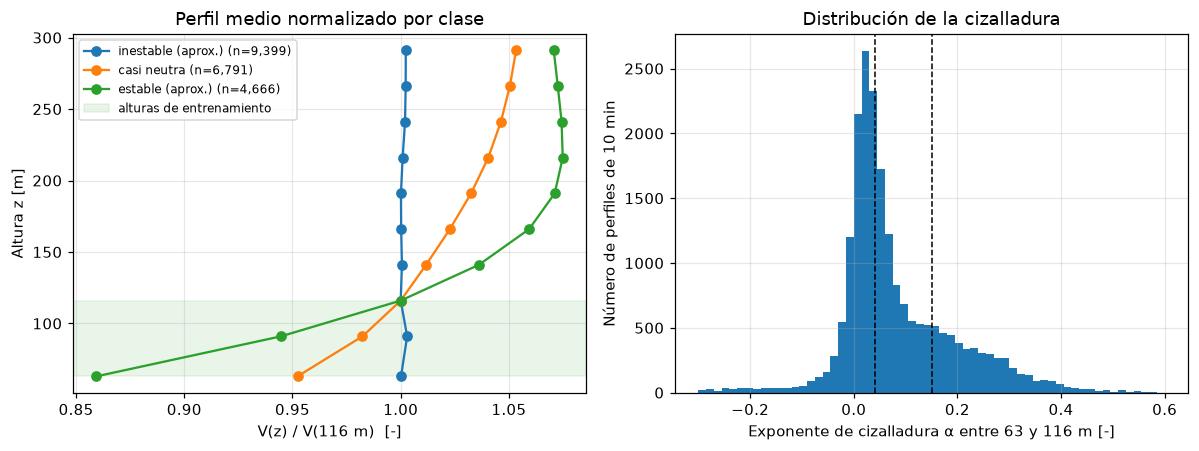

                     count   mean    50%
clase                                   
inestable (aprox.)  9399.0 -0.008  0.012
casi neutra         6791.0  0.080  0.071
estable (aprox.)    4666.0  0.250  0.233


In [4]:
CLASES = ["inestable (aprox.)", "casi neutra", "estable (aprox.)"]
d["clase"] = pd.cut(d.alpha, [-np.inf, 0.04, 0.15, np.inf], labels=CLASES)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for c in CLASES:
    m = d.loc[d.clase == c, COLS].mean()
    ax[0].plot(m.values / m["ws_116"], ALTURAS, "o-", label=f"{c} (n={int((d.clase == c).sum()):,})")
ax[0].axhspan(63, 116, color="tab:green", alpha=0.1, label="alturas de entrenamiento")
ax[0].set_xlabel("V(z) / V(116 m)  [-]"); ax[0].set_ylabel("Altura z [m]")
ax[0].set_title("Perfil medio normalizado por clase"); ax[0].legend(fontsize=8)

ax[1].hist(d.alpha, bins=np.linspace(-0.3, 0.6, 61), color="tab:blue")
for x in (0.04, 0.15): ax[1].axvline(x, color="k", ls="--", lw=1)
ax[1].set_xlabel("Exponente de cizalladura α entre 63 y 116 m [-]"); ax[1].set_ylabel("Número de perfiles de 10 min")
ax[1].set_title("Distribución de la cizalladura")
plt.tight_layout(); plt.show()
print(d.groupby("clase", observed=True).alpha.describe()[["count", "mean", "50%"]].round(3))

Observa la figura de la izquierda:

- En las clases **casi neutra** y **estable** el perfil **se curva y se aplana con la altura**: el aumento de velocidad entre 191 y 291 m es mucho menor que entre 63 y 116 m. En la clase estable el perfil medio llega a **disminuir** por encima de unos 220 m, la huella de chorros de bajo nivel.
- En la clase **inestable** el perfil es casi vertical: la mezcla convectiva iguala la velocidad en toda la columna.

Ni la ley de potencia ni la logarítmica (rectas en sus ejes) pueden reproducir esa curvatura. Ésta será la principal fuente de error al extrapolar.
Observa también que la clase "inestable" es la más numerosa: en 2017 el mar estuvo a menudo más cálido que el aire en este punto.


## 7. Diseño del experimento

- **Entrenamiento (por perfil):** sólo las alturas 63, 91 y 116 m, como una campaña con tres niveles bajos.
- **Test:** 141, 166, 191, 216 y 241 m, que **nunca** se usan para ajustar ningún método. Cubren el rango de buje y el disco del rotor.
- **Muestra de test:** 400 perfiles de 10 min elegidos al azar entre los días 22 a 31 de cada mes. Usamos una muestra y no los 20.000 perfiles porque cada perfil exige entrenar su propia red, y queremos que el notebook corra en minutos.
- Los días 1 a 20 quedan reservados para la "referencia con ventaja" de la sección 13 (dejamos el día 21 como separación para evitar autocorrelación entre conjuntos).

Cada método resuelve **400 problemas independientes**: dado un perfil de tres puntos, predecir cinco alturas superiores.

In [5]:
Z_TR = np.array([63, 91, 116], float)            # alturas medidas (entrenamiento)
Z_TE = np.array([141, 166, 191, 216, 241], float) # alturas a predecir (test)
N_TEST = 400
test = d[d.timestamp_utc.dt.day >= 22].sample(N_TEST, random_state=SEMILLA)
V_tr = test[[f"ws_{int(h)}" for h in Z_TR]].values   # (400, 3)
V_te = test[[f"ws_{int(h)}" for h in Z_TE]].values   # (400, 5)
clase_te = test.clase.values
print("Perfiles de test por clase:", pd.Series(clase_te).value_counts().to_dict())
print(f"Velocidad media a 116 m en test: {V_tr[:, 2].mean():.2f} m/s")

Perfiles de test por clase: {'casi neutra': 150, 'inestable (aprox.)': 145, 'estable (aprox.)': 105}
Velocidad media a 116 m en test: 10.57 m/s



## 8. Métodos clásicos

Ambos se ajustan por mínimos cuadrados con los tres puntos de cada perfil:

- Potencia: regresión lineal de $\ln V$ frente a $\ln z$; la pendiente es $\alpha$.
- Logarítmica: regresión lineal de $V$ frente a $\ln z$; la pendiente es $u_*/\kappa$ y $z_0 = \exp(-\text{ordenada}/\text{pendiente})$.

Añadimos una referencia trivial, **persistencia**: suponer que arriba sopla lo mismo que a 116 m. Cualquier método útil debe batirla.

In [6]:
KAPPA = 0.40

def ajuste_recta(x, Y):
    # Mínimos cuadrados de Y (n_perfiles, n_alturas) frente a x (n_alturas): devuelve ordenada y pendiente por perfil
    A = np.vstack([np.ones_like(x), x]).T
    c = np.linalg.lstsq(A, Y.T, rcond=None)[0]
    return c[0], c[1]

def ley_potencia(V, z, z_new):
    a, alfa = ajuste_recta(np.log(z), np.log(V))
    return np.exp(a[:, None] + alfa[:, None] * np.log(z_new)[None])

def ley_log(V, z, z_new):
    a, b = ajuste_recta(np.log(z), V)
    return a[:, None] + b[:, None] * np.log(z_new)[None]

pred = {
    "Persistencia (V116)": np.repeat(V_tr[:, 2:3], len(Z_TE), axis=1),
    "Ley de potencia": ley_potencia(V_tr, Z_TR, Z_TE),
    "Ley logarítmica": ley_log(V_tr, Z_TR, Z_TE),
}
a_log, b_log = ajuste_recta(np.log(Z_TR), V_tr)
z0_log = np.exp(-a_log / np.maximum(b_log, 1e-3))
print(f"u* mediana (ley log): {np.median(KAPPA * b_log):.3f} m/s")
print("z0 del ajuste log, percentiles 10/50/90 [m]:", np.percentile(z0_log, [10, 50, 90]))

u* mediana (ley log): 0.237 m/s
z0 del ajuste log, percentiles 10/50/90 [m]: [0.00000000e+00 1.31172687e-05 1.37461419e+00]


Fíjate en la $z_0$ que sale del ajuste logarítmico: su mediana es unas diez veces menor que el valor típico en el mar ($10^{-4}$ m) y varía en muchos órdenes de magnitud de un perfil a otro (en perfiles casi verticales, $z_0$ se vuelve diminuta). Cuando ajustamos la ley log entre 63 y 116 m, $z_0$ deja de ser una rugosidad física y pasa a ser un **parámetro efectivo** que absorbe la estabilidad y todo lo que la teoría no recoge. Es la primera pista de que imponer la teoría desde la superficie del mar puede no casar con lo medido a 60 a 120 m.


## 9. MLP sin física y PINN

**400 redes a la vez.** Cada perfil necesita su propia red (es su propio problema). Entrenarlas una a una sería lento, así que las **vectorizamos**: los pesos tienen una dimensión extra de tamaño 400 y usamos productos de matrices por lotes (`@` sobre tensores 3D). Cada red es independiente; sólo comparten el bucle de optimización.

Arquitectura de cada red: entrada $x=(\ln z - \ln 100)/3$, dos capas ocultas de 20 neuronas con `tanh`, salida multiplicada por la velocidad media medida del perfil ($V_{ref}$), de modo que la red trabaja con números de orden 1.

**Un detalle que nos costó un error real.** La primera versión de $\phi_m$ usaba `zeta.clamp(min=0)` en la rama estable. Como $1/L$ se inicializa en 0 (neutro), en ese punto el gradiente de `clamp` es **cero** y $L$ nunca se movía de neutro: la PINN entrenaba sin error aparente, pero sin aprender estabilidad. La versión de abajo usa `1 + 5*zeta` directamente. Moraleja: comprueba siempre que los parámetros físicos cambian durante el entrenamiento.

In [7]:
def phi_m(zeta):
    # Función de estabilidad de Businger-Dyer. Sin clamp en la rama estable: gradiente no nulo en zeta = 0
    inestable = (1 - 16 * zeta.clamp(max=0)).pow(-0.25)
    return torch.where(zeta >= 0, 1 + 5 * zeta, inestable)

class MLPporLotes(torch.nn.Module):
    # N redes 1 -> h -> h -> 1 independientes, evaluadas en paralelo
    def __init__(self, N, h=20):
        super().__init__()
        P = torch.nn.Parameter
        self.W1 = P(torch.randn(N, 1, h));               self.b1 = P(torch.zeros(N, 1, h))
        self.W2 = P(torch.randn(N, h, h) / math.sqrt(h)); self.b2 = P(torch.zeros(N, 1, h))
        self.W3 = P(torch.randn(N, h, 1) / math.sqrt(h)); self.b3 = P(torch.ones(N, 1, 1))  # salida inicial = V_ref
    def forward(self, x):                       # x: (N, M, 1) con M alturas por perfil
        h = torch.tanh(x @ self.W1 + self.b1)
        h = torch.tanh(h @ self.W2 + self.b2)
        return h @ self.W3 + self.b3            # (N, M, 1), en unidades de V_ref

S0, SS = math.log(100.0), 3.0                   # normalización de s = ln z
norm = lambda s: (s - S0) / SS

In [8]:
def entrenar(V_obs, z_obs, z_new, lam=0.0, contorno=True, pasos=1000, semilla=SEMILLA):
    # Entrena N redes (una por perfil). lam=0: MLP sin física. lam>0: PINN (A si contorno=True, B si no)
    torch.manual_seed(semilla)
    N = V_obs.shape[0]
    vt = torch.tensor(V_obs, dtype=torch.float32)
    vref = vt.mean(1, keepdim=True)                                  # (N, 1)
    red = MLPporLotes(N)
    # Parámetros físicos por perfil, iniciados con el ajuste logarítmico (arranque en caliente)
    a, b = ajuste_recta(np.log(z_obs), V_obs); b = np.maximum(b, 0.05)
    log_ust = torch.nn.Parameter(torch.tensor(np.log(KAPPA * b), dtype=torch.float32)[:, None])
    log_z0 = torch.nn.Parameter(torch.tensor(np.clip(-a / b, -14, -2), dtype=torch.float32)[:, None])
    inv_L = torch.nn.Parameter(torch.zeros(N, 1))                    # 1/L en unidades de 1/(100 m); 0 = neutro
    opt = torch.optim.Adam([{"params": red.parameters(), "lr": 5e-3},
                            {"params": [log_ust, log_z0, inv_L], "lr": 2e-2}])
    s_obs = torch.log(torch.tensor(z_obs, dtype=torch.float32))[None, :, None].expand(N, -1, -1)
    rejilla = torch.linspace(0, 1, 16)[None, :, None]                # 16 puntos de colocación por perfil
    for _ in range(pasos):
        opt.zero_grad()
        perdida = (((red(norm(s_obs))[..., 0] * vref - vt) / vref) ** 2).mean()          # término de datos
        if lam > 0:
            ust, z0 = torch.exp(log_ust), torch.exp(log_z0.clamp(-14, -2))
            s_ini = torch.log(z0)[:, :, None] if contorno else torch.full((N, 1, 1), math.log(40.0))
            s_c = (s_ini + (math.log(320.0) - s_ini) * rejilla).detach().requires_grad_(True)
            v_c = red(norm(s_c)) * vref[:, :, None]
            dv_ds = torch.autograd.grad(v_c.sum(), s_c, create_graph=True)[0][..., 0]     # dV/d ln z exacta
            zeta = torch.exp(s_c[..., 0]) * inv_L * 1e-2
            fisica = (((dv_ds - ust / KAPPA * phi_m(zeta)) / vref) ** 2).mean()           # residuo de MO
            if contorno:
                fisica = fisica + (red(norm(torch.log(z0)[:, :, None]))[..., 0] ** 2).mean()  # V(z0) = 0
                fisica = fisica + 1e-3 * ((log_z0 - torch.log(0.011 * ust**2 / 9.81)) ** 2).mean()  # Charnock suave
            perdida = perdida + lam * fisica
        perdida.backward(); opt.step()
    with torch.no_grad():
        s_new = torch.log(torch.tensor(z_new, dtype=torch.float32))[None, :, None].expand(N, -1, -1)
        V_pred = (red(norm(s_new))[..., 0] * vref).numpy()
    fis = {"u*": torch.exp(log_ust).detach().numpy()[:, 0], "1/L": inv_L.detach().numpy()[:, 0] * 1e-2}
    return V_pred, fis

Entrenamos las tres redes con $\lambda=1$ para las PINN. Tarda un par de minutos: cada PINN calcula derivadas de segundo orden (la derivada de la pérdida respecto a los pesos pasa a través de $\partial V/\partial \ln z$).

In [9]:
t = time.time()
pred["MLP sin física"], _ = entrenar(V_tr, Z_TR, Z_TE, lam=0.0)
print(f"MLP sin física: {time.time() - t:.0f} s"); t = time.time()
pred["PINN-A (completa)"], fisA = entrenar(V_tr, Z_TR, Z_TE, lam=1.0, contorno=True)
print(f"PINN-A: {time.time() - t:.0f} s"); t = time.time()
pred["PINN-B (sólo forma)"], fisB = entrenar(V_tr, Z_TR, Z_TE, lam=1.0, contorno=False)
print(f"PINN-B: {time.time() - t:.0f} s")
for nombre, f in [("PINN-A", fisA), ("PINN-B", fisB)]:
    p = np.percentile(f["1/L"], [10, 50, 90])
    print(f"{nombre}: 1/L percentiles 10/50/90 = {p.round(4)} 1/m  |  u* mediana = {np.median(f['u*']):.3f} m/s")

MLP sin física: 8 s


PINN-A: 19 s


PINN-B: 12 s
PINN-A: 1/L percentiles 10/50/90 = [-0.0064  0.0002  0.0011] 1/m  |  u* mediana = 0.293 m/s
PINN-B: 1/L percentiles 10/50/90 = [-0.0022 -0.0004 -0.    ] 1/m  |  u* mediana = 0.265 m/s



## 10. Resultados por altura

Misma muestra de test, mismas alturas, ningún método ha visto los datos de 141 a 241 m.

In [10]:
def tabla_metricas(pred, V_ref, alturas=Z_TE):
    filas = []
    for nombre, P in pred.items():
        e = P - V_ref
        for j, h in enumerate(alturas):
            filas.append({"método": nombre, "altura [m]": int(h),
                          "RMSE [m/s]": np.sqrt((e[:, j] ** 2).mean()), "sesgo [m/s]": e[:, j].mean()})
    return pd.DataFrame(filas)

met = tabla_metricas(pred, V_te)
rmse = met.pivot(index="método", columns="altura [m]", values="RMSE [m/s]")
sesgo = met.pivot(index="método", columns="altura [m]", values="sesgo [m/s]")
orden = rmse[241].sort_values().index
print("RMSE [m/s] por altura de test (ordenado por el error a 241 m)")
display(rmse.loc[orden].round(3))
print("Sesgo [m/s] = predicho - medido")
display(sesgo.loc[orden].round(3))

RMSE [m/s] por altura de test (ordenado por el error a 241 m)


altura [m],141,166,191,216,241
método,,,,,
MLP sin física,0.237,0.501,0.804,0.980,1.144
PINN-B (sólo forma),0.309,0.575,0.882,1.060,1.225
Ley logarítmica,0.296,0.574,0.888,1.079,1.266
PINN-A (completa),0.368,0.663,0.982,1.155,1.304
Ley de potencia,0.306,0.591,0.922,1.150,1.379
Persistencia (V116),0.412,0.809,1.161,1.334,1.465


Sesgo [m/s] = predicho - medido


altura [m],141,166,191,216,241
método,,,,,
MLP sin física,-0.015,-0.045,-0.043,0.008,0.065
PINN-B (sólo forma),0.040,0.047,0.083,0.166,0.253
Ley logarítmica,0.028,0.036,0.075,0.162,0.253
PINN-A (completa),-0.018,-0.018,0.019,0.106,0.200
Ley de potencia,0.053,0.085,0.152,0.267,0.388
Persistencia (V116),-0.194,-0.366,-0.482,-0.531,-0.560


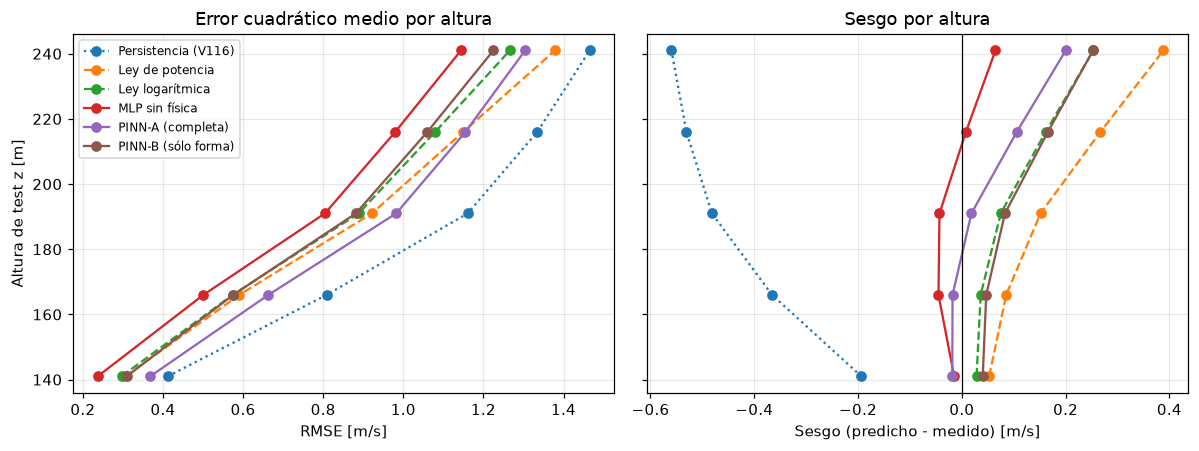

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
estilos = {"Persistencia (V116)": ":", "Ley de potencia": "--", "Ley logarítmica": "--"}
for nombre in pred:
    ls = estilos.get(nombre, "-")
    ax[0].plot(rmse.loc[nombre].values, Z_TE, ls, marker="o", label=nombre)
    ax[1].plot(sesgo.loc[nombre].values, Z_TE, ls, marker="o", label=nombre)
ax[0].set_xlabel("RMSE [m/s]"); ax[0].set_ylabel("Altura de test z [m]"); ax[0].set_title("Error cuadrático medio por altura")
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_xlabel("Sesgo (predicho - medido) [m/s]"); ax[1].set_title("Sesgo por altura")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura honesta de la tabla.**

- Todos los métodos baten a la persistencia, y el error crece con la distancia a la última medida, como era de esperar.
- **Con datos limpios y tres niveles, la PINN no gana.** La PINN-B (sólo forma) queda prácticamente empatada con la ley logarítmica; la PINN-A (completa, anclada en la superficie del mar) es algo peor.
- **El MLP sin física es el mejor aquí.** No es porque "sepa" meteorología: la `tanh` se satura y, fuera de los datos, la red tiende a **aplanar** el perfil. Por casualidad, eso se parece a la forma real (sección 6), que se aplana por encima de 150 m. Es un sesgo inductivo afortunado, no un mérito garantizado; en la sección 12 veremos que se rompe en cuanto los datos tienen ruido.
- Las leyes clásicas y las PINN **sobrestiman en las alturas altas** (sesgo de +0,2 a +0,4 m/s a 241 m): extrapolan una cizalladura de capa superficial a alturas donde el perfil real ya se ha aplanado. La persistencia, en cambio, subestima en más de 0,5 m/s.

¿Por qué la PINN-A es peor? Porque le pedimos que el perfil cumpla MO **desde $z_0$** (casi el nivel del mar) hasta 320 m y que pase por $V(z_0)=0$. Esa física es correcta cerca de la superficie, pero a 60 a 240 m estamos con frecuencia fuera de la capa superficial. Cuando la física impuesta es incorrecta para el rango de interés, añadirla **empeora** el resultado.


## 11. Resultados por clase de estabilidad y perfiles individuales

Desglosamos el RMSE a 191 m (altura de buje alta) por clase aproximada de estabilidad.

In [12]:
j191 = list(Z_TE).index(191)
filas = []
for nombre, P in pred.items():
    e = P[:, j191] - V_te[:, j191]
    fila = {"método": nombre}
    for c in CLASES:
        m = clase_te == c
        fila[f"RMSE {c}"] = np.sqrt((e[m] ** 2).mean())
        fila[f"sesgo {c}"] = e[m].mean()
    filas.append(fila)
por_clase = pd.DataFrame(filas).set_index("método").loc[orden]
display(por_clase.round(2))

,RMSE inestable (aprox.),sesgo inestable (aprox.),RMSE casi neutra,sesgo casi neutra,RMSE estable (aprox.),sesgo estable (aprox.)
método,,,,,,
MLP sin física,0.37,-0.10,0.52,-0.05,1.37,0.04
PINN-B (sólo forma),0.38,0.07,0.64,0.05,1.48,0.15
Ley logarítmica,0.34,-0.04,0.65,0.08,1.50,0.22
PINN-A (completa),0.48,0.28,0.70,0.11,1.63,-0.47
Ley de potencia,0.34,-0.03,0.66,0.11,1.57,0.46
Persistencia (V116),0.34,-0.04,0.75,-0.38,2.04,-1.23


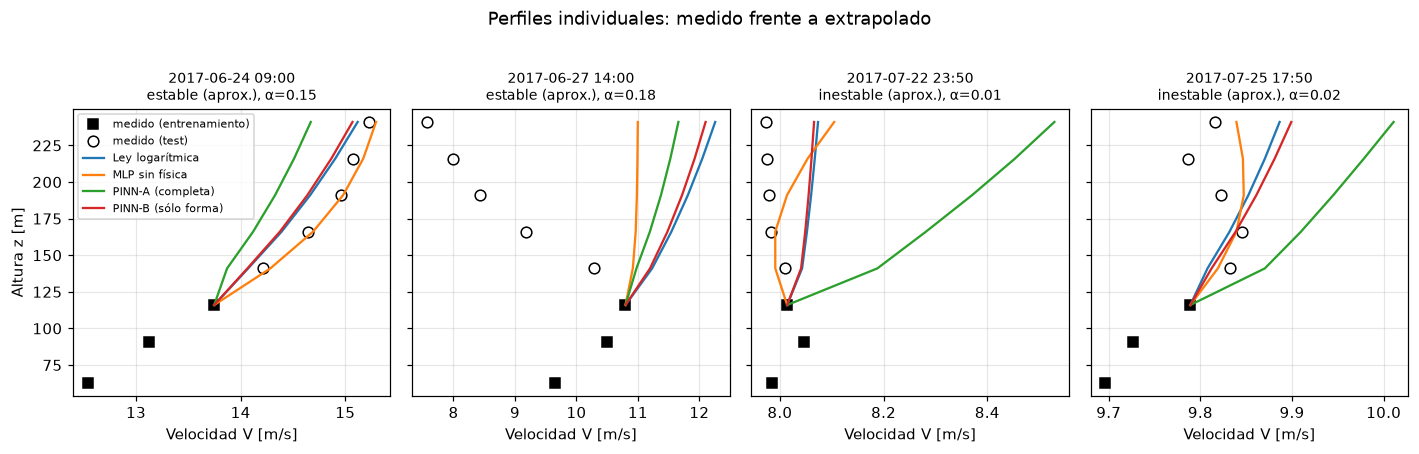

In [13]:
# Cuatro perfiles de ejemplo: dos de cada extremo de cizalladura
idx = list(np.where(clase_te == CLASES[2])[0][:2]) + list(np.where(clase_te == CLASES[0])[0][:2])
fig, axs = plt.subplots(1, 4, figsize=(13, 4), sharey=True)
for ax, i in zip(axs, idx):
    ax.plot(V_tr[i], Z_TR, "ks", ms=7, label="medido (entrenamiento)")
    ax.plot(V_te[i], Z_TE, "ko", mfc="none", ms=7, label="medido (test)")
    for nombre in ["Ley logarítmica", "MLP sin física", "PINN-A (completa)", "PINN-B (sólo forma)"]:
        ax.plot(np.r_[V_tr[i, -1], pred[nombre][i]], np.r_[116, Z_TE], "-", label=nombre)
    ax.set_title(f"{test.timestamp_utc.iloc[i]:%Y-%m-%d %H:%M}\n{clase_te[i]}, α={test.alpha.iloc[i]:.2f}", fontsize=9)
    ax.set_xlabel("Velocidad V [m/s]")
axs[0].set_ylabel("Altura z [m]"); axs[0].legend(fontsize=7, loc="upper left")
plt.suptitle("Perfiles individuales: medido frente a extrapolado", y=1.02)
plt.tight_layout(); plt.show()

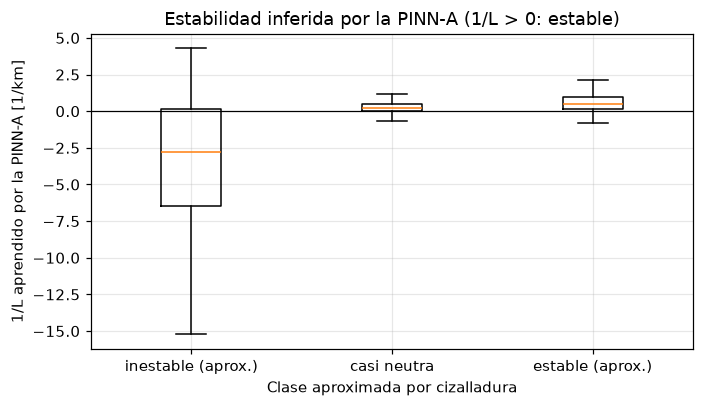

In [14]:
# ¿Qué estabilidad infiere la PINN-A? Comparamos 1/L aprendido con la clase por cizalladura
fig, ax = plt.subplots(figsize=(6.5, 3.8))
datos_box = [fisA["1/L"][clase_te == c] * 1000 for c in CLASES]
ax.boxplot(datos_box, showfliers=False)
ax.set_xticks([1, 2, 3], CLASES)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("1/L aprendido por la PINN-A [1/km]")
ax.set_xlabel("Clase aproximada por cizalladura")
ax.set_title("Estabilidad inferida por la PINN-A (1/L > 0: estable)")
plt.tight_layout(); plt.show()

**Qué vemos.**

- En la clase **estable** todos los métodos fallan mucho más: el RMSE es entre dos y cuatro veces el de las otras clases. Con atmósfera estable aparecen chorros de bajo nivel y capas límite bajas: el perfil puede incluso decrecer con la altura. Con tres puntos por debajo de 116 m no hay información para anticiparlo, con o sin física.
- En la clase **inestable**, la persistencia y las leyes clásicas ya son buenas (el perfil es casi vertical) y la PINN-A es la peor, con sesgo positivo: en varios perfiles se curva hacia fuera (tercer y cuarto ejemplo). Es el síntoma del conflicto entre los datos y la condición $V(z_0)=0$ en la superficie del mar.
- El $1/L$ que aprende la PINN-A tiende a ordenarse con la clase de cizalladura (más positivo en la clase estable), lo que indica que el problema inverso extrae algo de información física. Pero con tres puntos el problema está mal condicionado: $u_*$, $z_0$ y $L$ se compensan entre sí y los valores individuales no deben interpretarse como mediciones de estabilidad.


## 12. Experimento: ruido y pocos niveles de medida

En la práctica los datos no son perfectos: un anemómetro mal calibrado, la sombra de la torre o un lidar flotante en movimiento añaden error. Y a veces sólo hay **dos** alturas útiles. Repetimos la comparación en cuatro escenarios:

| Escenario | Alturas de entrenamiento | Ruido añadido |
|---|---|---|
| 1 | 63, 91, 116 m | ninguno |
| 2 | 63, 91, 116 m | gaussiano, $\sigma=0{,}3$ m/s ($\sigma$ es la desviación típica del ruido) |
| 3 | 63, 91 m | ninguno |
| 4 | 63, 91 m | gaussiano, $\sigma=0{,}3$ m/s |

El ruido es una única realización con semilla fija, idéntica para todos los métodos. Evaluamos siempre contra las medidas **sin ruido** a 141 a 241 m. Para no repetir el cálculo, el escenario 1 reutiliza los resultados de la sección 10.

In [15]:
rng = np.random.default_rng(SEMILLA)
ruido = rng.normal(0, 0.3, V_tr.shape)
escenarios = {"1) 3 niveles, sin ruido": ([0, 1, 2], 0.0), "2) 3 niveles, ruido 0,3": ([0, 1, 2], 1.0),
              "3) 2 niveles, sin ruido": ([0, 1], 0.0),    "4) 2 niveles, ruido 0,3": ([0, 1], 1.0)}
res = {}
t = time.time()
for esc, (cols, k) in escenarios.items():
    if esc.startswith("1"):
        P = {m: pred[m] for m in ["Ley de potencia", "Ley logarítmica", "MLP sin física", "PINN-A (completa)", "PINN-B (sólo forma)"]}
    else:
        Vn, zn = V_tr[:, cols] + k * ruido[:, cols], Z_TR[cols]
        P = {"Ley de potencia": ley_potencia(Vn, zn, Z_TE), "Ley logarítmica": ley_log(Vn, zn, Z_TE),
             "MLP sin física": entrenar(Vn, zn, Z_TE, lam=0.0)[0],
             "PINN-A (completa)": entrenar(Vn, zn, Z_TE, lam=1.0, contorno=True)[0],
             "PINN-B (sólo forma)": entrenar(Vn, zn, Z_TE, lam=1.0, contorno=False)[0]}
    res[esc] = {m: np.sqrt(((p - V_te) ** 2).mean(axis=0)) for m, p in P.items()}
print(f"Tiempo del experimento: {time.time() - t:.0f} s")
tabla_esc = pd.DataFrame({esc: {m: r[j191] for m, r in rr.items()} for esc, rr in res.items()})
print("RMSE [m/s] a 191 m por escenario")
display(tabla_esc.round(3))

Tiempo del experimento: 100 s
RMSE [m/s] a 191 m por escenario


,"1) 3 niveles, sin ruido","2) 3 niveles, ruido 0,3","3) 2 niveles, sin ruido","4) 2 niveles, ruido 0,3"
Ley de potencia,0.922,1.133,1.214,1.746
Ley logarítmica,0.888,1.074,1.127,1.571
MLP sin física,0.804,1.245,1.115,1.524
PINN-A (completa),0.982,1.066,1.225,1.282
PINN-B (sólo forma),0.882,1.027,1.114,1.438


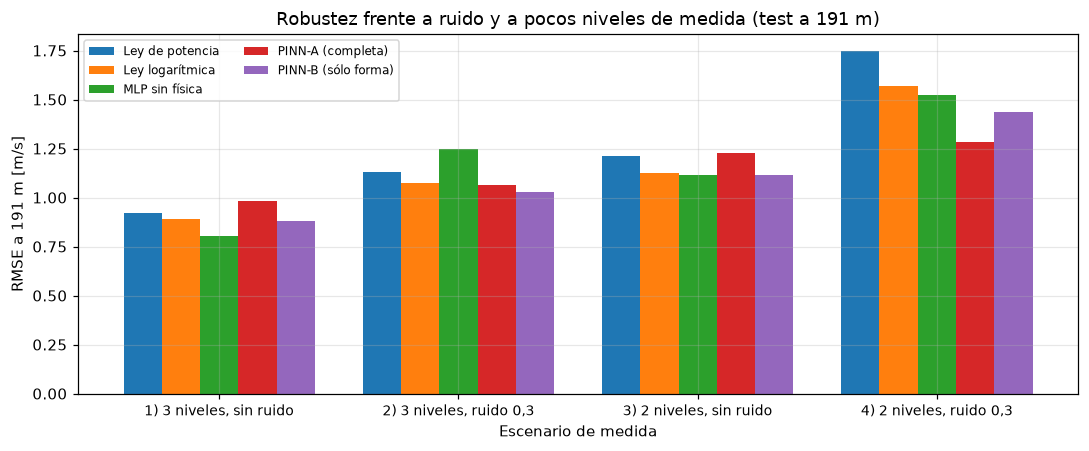

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.2))
metodos = list(tabla_esc.index); x = np.arange(len(tabla_esc.columns)); w = 0.16
for k, m in enumerate(metodos):
    ax.bar(x + (k - 2) * w, tabla_esc.loc[m].values, w, label=m)
ax.set_xticks(x, tabla_esc.columns, fontsize=9)
ax.set_ylabel("RMSE a 191 m [m/s]"); ax.set_xlabel("Escenario de medida")
ax.set_title("Robustez frente a ruido y a pocos niveles de medida (test a 191 m)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Aquí está la lección central del notebook.**

- **Con ruido, el MLP sin física se hunde.** Con tres puntos y libertad total, la red pasa exactamente por los datos ruidosos y extrapola el ruido. Su "suerte" del escenario 1 desaparece.
- **Con ruido, la física empieza a ayudar.** Con tres niveles ruidosos la PINN-B es la mejor y la PINN-A queda al nivel de la ley logarítmica. La ecuación de MO actúa como **regularizador**: sólo admite perfiles con forma físicamente plausible, y el ruido no puede doblar el perfil a voluntad. La ventaja es modesta (unos 5 cm/s frente a la ley log a 191 m) y, con una sola realización de ruido, no debe sobreinterpretarse.
- **Con dos niveles y ruido, la PINN-A (completa) es claramente la mejor.** La condición de contorno $V(z_0)\approx 0$ y la relación de Charnock aportan, en la práctica, un **punto de información adicional en la superficie del mar**. Es exactamente lo que falta cuando sólo hay dos medidas ruidosas. Esa misma condición era la que la perjudicaba con datos limpios.
- Con dos niveles sin ruido, todos los métodos quedan muy parecidos: dos puntos no contienen información sobre la curvatura.

Regla práctica: **la física ayuda cuando los datos son escasos o ruidosos, y estorba cuando los datos son buenos y la física impuesta no describe bien el rango de alturas de interés.** El parámetro $\lambda$ es la perilla que regula ese equilibrio.


## 13. Una referencia "con ventaja": aprender de un lidar alto

Todo lo anterior supone que en el emplazamiento sólo hay medidas bajas. Si existe un periodo con un lidar que mide **también** a las alturas altas (aquí, los días 1 a 20 de cada mes), un modelo puramente estadístico puede aprender la relación entre el perfil bajo y el alto. Es la lógica de los métodos de correlación entre medidas.

Usamos una regresión lineal regularizada (Ridge) que predice el cociente $V(z)/V(116)$ a partir de las tres velocidades bajas y de los dos exponentes de cizalladura locales. **No es comparable en igualdad de condiciones**: ha visto datos reales a 141 a 241 m (de otros días).

In [17]:
from sklearn.linear_model import Ridge

def rasgos(Vb):
    # Velocidades bajas y exponentes de cizalladura entre pares de alturas
    a1 = np.log(Vb[:, 1] / Vb[:, 0]) / np.log(91 / 63)
    a2 = np.log(Vb[:, 2] / Vb[:, 1]) / np.log(116 / 91)
    return np.column_stack([Vb, a1, a2])

entreno = d[d.timestamp_utc.dt.day <= 20]
Vb_e = entreno[[f"ws_{int(h)}" for h in Z_TR]].values
Va_e = entreno[[f"ws_{int(h)}" for h in Z_TE]].values
modelo = Ridge(alpha=1.0).fit(rasgos(Vb_e), Va_e / Vb_e[:, 2:3])
pred_ridge = modelo.predict(rasgos(V_tr)) * V_tr[:, 2:3]
e = pred_ridge - V_te
print(f"Entrenado con {len(entreno):,} perfiles completos de los días 1 a 20")
display(pd.DataFrame({"RMSE [m/s]": np.sqrt((e ** 2).mean(0)), "sesgo [m/s]": e.mean(0)},
                     index=pd.Index(Z_TE.astype(int), name="altura [m]")).T.round(3))

Entrenado con 13,855 perfiles completos de los días 1 a 20


altura [m],141,166,191,216,241
RMSE [m/s],0.232,0.515,0.838,1.008,1.149
sesgo [m/s],-0.032,-0.104,-0.166,-0.183,-0.195


Resultado quizá sorprendente: **la ventaja es pequeña**. Con casi 14.000 perfiles completos de entrenamiento, el Ridge queda al nivel del MLP por perfil en RMSE (unos 1,15 m/s a 241 m) y con un sesgo negativo de unos -0,2 m/s arriba, porque la relación media entre perfil bajo y alto de unos días no se transfiere exactamente a otros.

La lección es de **información**, no de modelo: tres velocidades por debajo de 116 m apenas contienen información sobre lo que ocurre a 240 m en ese momento (chorros de bajo nivel, altura de la capa límite). Ni la física ni un modelo estadístico pueden inventar esa información. Un modelo más flexible (árboles, redes) podría reducir algo el sesgo y queda como ejercicio, pero la única forma de eliminar el error en un instante concreto es **medir a esa altura**.


## 14. ¿Cuándo merece la pena una PINN y cuándo no? Cuatro sitios reales

Hasta aquí el resultado honesto es incómodo para la PINN: con datos limpios y tres alturas gana el MLP sin física, y la física sólo ayuda con ruido o con dos alturas. Eso no basta para decidir en un proyecto real. En esta segunda parte preguntamos de forma sistemática **en qué circunstancias la PINN mejora claramente a la alternativa sin física, y en cuáles no**, variando una cosa cada vez:

| Sección | Pregunta | Qué variamos |
|---|---|---|
| 15 | ¿Cuántos perfiles completos hacen falta? | número de perfiles con todas las alturas para entrenar (de 3 a todos) |
| 16 | ¿Y si la física no describe bien el sitio? | cuatro sitios reales: dos plataformas en el mar, un faro cerca de la costa y una colina en tierra; con y sin ruido |
| 17 | ¿Y lejos del rango medido? | extrapolar muy por encima y hacia la superficie |
| 18 | ¿Y si lo que quiero es el parámetro físico? | estimar $u_*$ y $L$ con perfiles muy ruidosos |
| 19 | ¿Se transfiere lo aprendido a otro sitio? | entrenar en un sitio, aplicar en otro con pocos perfiles |
| 20 | Resumen | mapa de regímenes y tabla de decisión |

**Reglas de juego.** Mismos perfiles de test para todos los métodos de cada prueba, alturas de test nunca usadas para ajustar, semillas fijas y, donde hay muestreo, tres repeticiones con subconjuntos distintos. Comparamos la PINN con **la mejor alternativa sin PINN** (ley de potencia, ley logarítmica, MLP o Ridge según la prueba), no con la peor.


### Los cuatro sitios

| Sitio | Tipo | Alturas [m] | Periodo | Fuente y licencia |
|---|---|---|---|---|
| **EPL** | plataforma fija en el mar, unos 50 km de la costa | 63 a 291 (10) | 2017 | portal de mediciones de viento marino de TNO (sección 5); sin licencia explícita |
| **K13A** | plataforma fija en el mar, unos 100 km de la costa | 63 a 291 (10) | 2017 | mismo portal y formato que EPL (`K13A-STAT_V2-2017-Y`); sin licencia explícita |
| **LEG (Lichteiland Goeree)** | faro sobre el mar, unos 10 km de la costa | 62 a 290 (10) | enero a junio de 2017 (no hay más en el fichero) | mismo portal (`LEG-STAT-2017-Y`), otro modelo de lidar y otro formato; sin licencia explícita |
| **Altahullion** | lidar en tierra, en un parque eólico sobre una sierra de Irlanda del Norte (terreno complejo) | 18 a 203 (11) | septiembre de 2025 a febrero de 2026 | conjunto abierto del parque, Zenodo `doi:10.5281/zenodo.19948235`, licencia CC BY 4.0 (Creative Commons Atribución) |

Extractos en `datos/` (sólo velocidades medias de 10 min, una dirección y un indicador de calidad): `k13a_lidar_2017_10min.csv.gz`, `leg_lidar_2017_10min.csv.gz` y `altahullion_lidar_10min.csv.gz`.

Notas de calidad:

- **LEG** informa la disponibilidad por altura; exigimos al menos un 80 % en todas las alturas, y eso deja sólo el 38 % de los registros (unos 4.300 perfiles). Es suficiente, pero la muestra puede favorecer situaciones con buena señal en toda la columna.
- **Altahullion** está a unos 130 m de un aerogenerador de 49 m de buje y 62 m de rotor: las alturas de 18 a 80 m pueden estar afectadas por su estela, y la colina acelera el flujo cerca del suelo. Ahí la teoría de MO, pensada para terreno llano y homogéneo, **no tiene por qué valer**: es nuestro caso de "física mal especificada".
- Descartamos otros candidatos: un mástil marino con varias alturas cuyos datos brutos no forman parte de este extracto (sólo hay datos de turbinas) y los mástiles de un emplazamiento de ensayos en tierra con sólo dos alturas útiles y licencia sin confirmar.

Mismo diseño que en EPL: entrenamiento con las tres alturas más bajas comparables (en Altahullion 48, 68 y 98 m, para que la altura de test más alta sea también unas dos veces la última medida), test por encima, perfiles de entrenamiento de los días 1 a 20 y de test de los días 22 a 31.

**¿Está la física bien especificada?** Antes de entrenar nada, medimos cuánto se aleja cada sitio de MO: para cada perfil de test ajustamos el mejor perfil de MO (con $u_*$, $L$ y $z_0$ libres) a **todas** las alturas y miramos el error que queda. Si ni el mejor perfil de MO se ajusta, imponer MO no puede ayudar.

In [18]:
# Funciones de Monin-Obukhov integradas (para ajustes clásicos y para el banco con verdad conocida)
G_GRAV = 9.81

def psi_m(zeta):
    # Corrección de estabilidad integrada: lineal en estable, Paulson en inestable
    x = np.power(np.clip(1 - 16 * np.minimum(zeta, 0), 1e-9, None), 0.25)
    inest = 2 * np.log((1 + x) / 2) + np.log((1 + x**2) / 2) - 2 * np.arctan(x) + np.pi / 2
    return np.where(zeta >= 0, -5 * zeta, inest)

def perfil_mo(z, ust, invL, z0=None):
    # V(z) = u*/kappa [ln(z/z0) - psi_m(z/L)]; sin z0 usa Charnock (mar)
    z0 = 0.011 * ust**2 / G_GRAV if z0 is None else z0
    return ust / KAPPA * (np.log(z / z0) - psi_m(z * invL))

def ajuste_mo(z, Vobs):
    # Mínimos cuadrados no lineales de un perfil con Charnock: devuelve (u*, 1/L) y el RMSE del ajuste
    from scipy.optimize import least_squares
    r = least_squares(lambda p: perfil_mo(z, p[0], p[1]) - Vobs, [0.3, 0.0], bounds=([0.01, -0.05], [2.0, 0.05]))
    return r.x, np.sqrt((r.fun ** 2).mean())

def ajuste_mo_z0_libre(z, V):
    # MO con z0 libre para muchos perfiles a la vez: para cada 1/L de una rejilla, V = A (ln z - psi_m) + C es lineal
    rejilla = np.r_[-np.logspace(-5, np.log10(0.02), 60)[::-1], 0, np.logspace(-5, np.log10(0.02), 60)]
    mejor = np.full(len(V), np.inf)
    for g in rejilla:
        X = np.log(z) - psi_m(z * g)
        Xc, Vc = X - X.mean(), V - V.mean(1, keepdims=True)
        A = np.maximum((Vc * Xc).sum(1) / (Xc ** 2).sum(), 1e-6)       # pendiente u*/kappa (positiva)
        err = np.sqrt(((Vc - A[:, None] * Xc) ** 2).mean(1))
        mejor = np.minimum(mejor, err)
    return mejor

def preparar_sitio(nombre, ruta, z_tr, z_te, calidad, n_test=400):
    # Mismo control de calidad que en EPL; entrenamiento días 1 a 20, test días 22 a 31
    df_s = pd.read_csv(ruta, parse_dates=["timestamp_utc"])
    cols_v = [c for c in df_s.columns if c.startswith("ws_")]
    a = np.log(df_s[f"ws_{z_tr[2]}"] / df_s[f"ws_{z_tr[0]}"]) / np.log(z_tr[2] / z_tr[0])
    ok = (((df_s[cols_v] > 0) & (df_s[cols_v] < 40)).all(axis=1) & (df_s[f"ws_{z_tr[0]}"] >= 4)
          & a.between(-0.5, 1.0) & calidad(df_s))
    ds = df_s[ok].assign(alpha=a[ok])
    pool_s = ds[ds.timestamp_utc.dt.day <= 20]
    test_s = ds[ds.timestamp_utc.dt.day >= 22].sample(n_test, random_state=SEMILLA)
    col = lambda zz: [f"ws_{int(h)}" for h in zz]
    return dict(nombre=nombre, z_tr=np.array(z_tr, float), z_te=np.array(z_te, float), d=ds, n_bruto=len(df_s),
                z_todas=np.array([int(c[3:]) for c in cols_v], float), test=test_s,
                Vp_tr=pool_s[col(z_tr)].values, Vp_te=pool_s[col(z_te)].values,
                Vt_tr=test_s[col(z_tr)].values, Vt_te=test_s[col(z_te)].values)

epl_pool = d[d.timestamp_utc.dt.day <= 20]
SITIOS = {
    "EPL (mar, 50 km)": dict(nombre="EPL (mar, 50 km)", z_tr=Z_TR, z_te=Z_TE, d=d, n_bruto=len(df), test=test,
                             z_todas=np.array(ALTURAS, float),
                             Vp_tr=epl_pool[[f"ws_{int(h)}" for h in Z_TR]].values,
                             Vp_te=epl_pool[[f"ws_{int(h)}" for h in Z_TE]].values, Vt_tr=V_tr, Vt_te=V_te),
    "K13A (mar, 100 km)": preparar_sitio("K13A (mar, 100 km)", "datos/k13a_lidar_2017_10min.csv.gz",
                             [63, 91, 116], [141, 166, 191, 216, 241],
                             lambda x: (x.paquetes_min >= 20) & (x.lluvia_pct.fillna(0) <= 10)),
    "LEG (costa, 10 km)": preparar_sitio("LEG (costa, 10 km)", "datos/leg_lidar_2017_10min.csv.gz",
                             [62, 90, 115], [140, 165, 190, 215, 240],
                             lambda x: x.disponibilidad_min_pct >= 80),
    "Altahullion (colina)": preparar_sitio("Altahullion (colina)", "datos/altahullion_lidar_10min.csv.gz",
                             [48, 68, 98], [141, 203],
                             lambda x: x.paquetes_min >= 20),
}

# ¿Cuánto se parece cada sitio a Monin-Obukhov? Ajuste de MO (z0 libre) a TODAS las alturas de los perfiles de test
N_PP = 100                     # perfiles de test usados en los experimentos por perfil (los mismos para todos los métodos)
filas = []
for nombre, s in SITIOS.items():
    Vfull = s["test"][[f"ws_{int(h)}" for h in s["z_todas"]]].values
    err = ajuste_mo_z0_libre(s["z_todas"], Vfull)
    filas.append({"sitio": nombre, "perfiles brutos": s["n_bruto"], "tras control": len(s["d"]),
                  "entrenamiento (días 1-20)": len(s["Vp_tr"]),
                  "alturas medidas [m]": f"{int(s['z_tr'][0])}-{int(s['z_tr'][-1])}",
                  "alturas de test [m]": f"{int(s['z_te'][0])}-{int(s['z_te'][-1])}",
                  "α mediana": round(float(np.median(s["d"].alpha)), 3),
                  "error ajuste MO, mediana [m/s]": round(float(np.median(err)), 3),
                  "% perfiles con error MO > 0,2 m/s": round(100 * float((err > 0.2).mean()), 1)})
    s["err_mo"] = err
tabla_sitios = pd.DataFrame(filas).set_index("sitio")
display(tabla_sitios)

,perfiles brutos,tras control,entrenamiento (días 1-20),alturas medidas [m],alturas de test [m],α mediana,"error ajuste MO, mediana [m/s]","% perfiles con error MO > 0,2 m/s"
sitio,,,,,,,,
"EPL (mar, 50 km)",24071,20856,13855,63-116,141-241,0.047,0.132,36.0
"K13A (mar, 100 km)",48680,42694,28211,63-116,141-241,0.071,0.099,26.5
"LEG (costa, 10 km)",11494,4325,2815,62-115,140-240,0.047,0.068,16.0
Altahullion (colina),14413,9644,6433,48-98,141-203,0.244,0.187,48.0


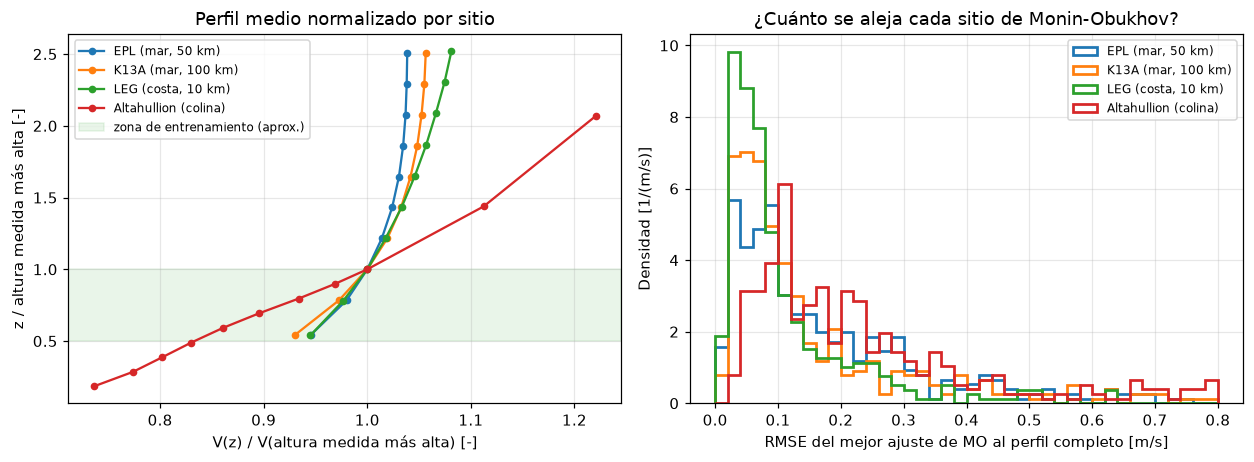

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
for nombre, s in SITIOS.items():
    zt = s["z_todas"]; m = s["d"][[f"ws_{int(h)}" for h in zt]].mean()
    ax[0].plot(m.values / m[f"ws_{int(s['z_tr'][-1])}"], zt / s["z_tr"][-1], "o-", ms=4, label=nombre)
ax[0].axhspan(0.5, 1.0, color="tab:green", alpha=0.1, label="zona de entrenamiento (aprox.)")
ax[0].set_xlabel("V(z) / V(altura medida más alta) [-]"); ax[0].set_ylabel("z / altura medida más alta [-]")
ax[0].set_title("Perfil medio normalizado por sitio"); ax[0].legend(fontsize=8)
bins = np.linspace(0, 0.8, 41)
for nombre, s in SITIOS.items():
    ax[1].hist(s["err_mo"], bins=bins, histtype="step", lw=1.8, density=True, label=nombre)
ax[1].set_xlabel("RMSE del mejor ajuste de MO al perfil completo [m/s]"); ax[1].set_ylabel("Densidad [1/(m/s)]")
ax[1].set_title("¿Cuánto se aleja cada sitio de Monin-Obukhov?"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.**

- Por error del mejor ajuste de MO, el orden es LEG (mediana 0,07 m/s), K13A (0,10), EPL (0,13) y Altahullion (0,19). En Altahullion casi la mitad de los perfiles se separan más de 0,2 m/s del mejor perfil de MO, incluso con tres parámetros libres.
- La colina tiene una cizalladura mucho mayor (α mediana 0,24 frente a 0,05 a 0,07 en el mar) y un perfil medio que sigue creciendo con fuerza por encima de la última medida.
- EPL, con más casos de chorro de bajo nivel y capa estable (sección 6), se aleja de MO más que K13A, que está más lejos de la costa.


## 15. Curva de aprendizaje: cuántos perfiles completos hacen falta

Hasta ahora cada perfil tenía su propia red, entrenada sólo con sus tres puntos. Eso no aprovecha que, a menudo, existe **un periodo con medidas altas** (un lidar alto durante unas semanas). Ahora entrenamos **una red global** para todos los perfiles:

- Entrada: altura relativa $\ln(z/z_{top})$ (con $z_{top}$ la altura medida más alta), la velocidad en $z_{top}$ y los cocientes $V_{63}/V_{116}$ y $V_{91}/V_{116}$. Salida: $V(z)/V(z_{top})$.
- Datos: $N$ **perfiles completos** (las 8 alturas de 63 a 241 m) más las **alturas bajas de todos los perfiles** del periodo de entrenamiento, que siempre se miden.
- **MLP global**: sólo esa pérdida de datos.
- **PINN global**: añade el residuo de MO en alturas de colocación (de 0,35 a 2,75 veces $z_{top}$) sobre los perfiles sin alturas altas. Una segunda red pequeña da $u_*$ y $1/L$ de cada perfil a partir de sus rasgos (inversión "amortizada"). Es aprendizaje **semisupervisado**: la física aporta información donde no hay etiquetas.
- **Ridge** (sección 13) con los mismos subconjuntos, como referencia lineal sin física.

Para cada $N$ (3, 10, 30, 100, 1000 y todos) repetimos tres veces con subconjuntos y semillas distintos; las bandas van del mínimo al máximo de las tres repeticiones. Test: los mismos 400 perfiles de la sección 10. Las líneas horizontales son los métodos por perfil, que no necesitan perfiles completos.

In [20]:
class RedPorLotesD(torch.nn.Module):
    # K redes independientes d -> h -> h -> salidas, evaluadas en paralelo (una por configuración)
    def __init__(self, K, d, h=32, salidas=1, sesgo_salida=1.0):
        super().__init__()
        P = torch.nn.Parameter
        self.W1 = P(torch.randn(K, d, h) / math.sqrt(d)); self.b1 = P(torch.zeros(K, 1, h))
        self.W2 = P(torch.randn(K, h, h) / math.sqrt(h)); self.b2 = P(torch.zeros(K, 1, h))
        self.W3 = P(torch.randn(K, h, salidas) * 0.1 / math.sqrt(h)); self.b3 = P(torch.full((K, 1, salidas), sesgo_salida))
    def forward(self, x):
        h = torch.tanh(x @ self.W1 + self.b1)
        h = torch.tanh(h @ self.W2 + self.b2)
        return h @ self.W3 + self.b3

def rasgos_red(Vb):
    # Entradas por perfil: velocidad en la altura medida más alta y cocientes de las dos inferiores respecto a ella
    return np.column_stack([Vb[:, 2] / 10 - 1, 5 * (Vb[:, 0] / Vb[:, 2] - 1), 5 * (Vb[:, 1] / Vb[:, 2] - 1)]).astype(np.float32)

def _entrada(F, s):
    # F (K, n, 3) rasgos por perfil; s (K, n, M) alturas relativas ln(z/z_top) -> (K, n*M, 4)
    K, n, M = s.shape
    return torch.cat([s.reshape(K, n * M, 1), F[:, :, None, :].expand(-1, -1, M, -1).reshape(K, n * M, 3)], -1)

def entrenar_global(sitio, subconjuntos, lam=0.0, pasos=800, semilla=SEMILLA, inicio=None, B=64, BU=64, NC=6):
    # Una red global por subconjunto de perfiles completos (todas en paralelo).
    # Datos: los perfiles completos del subconjunto + las alturas bajas de TODO el periodo de entrenamiento.
    # lam > 0 añade el residuo de MO en alturas de colocación de esos perfiles sin alturas altas (PINN).
    torch.manual_seed(semilla); rng = np.random.default_rng(semilla)
    K, z_tr, z_te = len(subconjuntos), sitio["z_tr"], sitio["z_te"]
    z_top = z_tr[-1]
    red, par = RedPorLotesD(K, 4), RedPorLotesD(K, 3, h=16, salidas=2, sesgo_salida=0.0)
    if inicio is not None:                  # transferencia: copiar en las K redes los pesos de la red origen k
        for dst, (src, k) in zip((red, par), inicio):
            for p_dst, p_src in zip(dst.parameters(), src.parameters()):
                p_dst.data[:] = p_src.data[k]
    opt = torch.optim.Adam(list(red.parameters()) + list(par.parameters()), lr=3e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, max(pasos, 1))
    Vp = np.c_[sitio["Vp_tr"], sitio["Vp_te"]]
    Fp = torch.tensor(rasgos_red(sitio["Vp_tr"]))
    Rp = torch.tensor(Vp / Vp[:, 2:3], dtype=torch.float32)            # perfil en unidades de V(z_top)
    s_tod = torch.tensor(np.log(np.r_[z_tr, z_te] / z_top), dtype=torch.float32)
    il = torch.tensor(np.stack([rng.choice(s, (pasos, B)) for s in subconjuntos]))   # (K, pasos, B) etiquetados
    iu = torch.tensor(rng.integers(0, len(Fp), (pasos, K, BU)))                       # sólo alturas bajas
    s_lo, s_hi = math.log(0.35), math.log(2.75)                                     # rango de colocación
    for paso in range(pasos):
        opt.zero_grad()
        i, u = il[:, paso], iu[paso]
        perd = ((red(_entrada(Fp[i], s_tod.expand(K, B, -1)))[..., 0] - Rp[i].reshape(K, -1)) ** 2).mean()
        perd = perd + ((red(_entrada(Fp[u], s_tod[:3].expand(K, BU, -1)))[..., 0] - Rp[u][..., :3].reshape(K, -1)) ** 2).mean()
        if lam > 0:
            s_c = (s_lo + (s_hi - s_lo) * torch.rand(K, BU, NC)).requires_grad_(True)
            r_c = red(_entrada(Fp[u], s_c))[..., 0]
            dr = torch.autograd.grad(r_c.sum(), s_c, create_graph=True)[0]         # dr/d ln z exacta
            p = par(Fp[u])                                                        # (K, BU, 2)
            pend, invL = 0.06 * torch.exp(p[..., :1]), p[..., 1:] * 1e-2            # u*/(kappa V_top) y 1/L [1/m]
            perd = perd + lam * ((dr - pend * phi_m(z_top * torch.exp(s_c) * invL)) ** 2).mean()
        perd.backward(); opt.step(); sched.step()
    with torch.no_grad():
        Ft = torch.tensor(rasgos_red(sitio["Vt_tr"]))[None].expand(K, -1, -1)
        st = torch.tensor(np.log(sitio["z_te"] / z_top), dtype=torch.float32).expand(K, len(sitio["Vt_tr"]), -1)
        R = red(_entrada(Ft, st))[..., 0].reshape(K, -1, len(z_te)).numpy()
        p = par(Ft).numpy()
    fis = {"u*": KAPPA * 0.06 * np.exp(p[..., 0]) * sitio["Vt_tr"][None, :, 2], "1/L": p[..., 1] * 1e-2}
    return R * sitio["Vt_tr"][None, :, 2:3], (red, par), fis

def subconjuntos_para(sitio, tamanos, reps, semilla=SEMILLA):
    # Subconjuntos aleatorios de perfiles completos de entrenamiento: reps repeticiones por tamaño
    rng = np.random.default_rng(semilla); n = len(sitio["Vp_tr"])
    return [rng.choice(n, min(N, n), replace=False) for N in tamanos for _ in range(reps)]

def rmse_alturas(P, V_ref):
    # RMSE por altura; P puede tener una dimensión extra delante (configuraciones)
    return np.sqrt(((P - V_ref) ** 2).mean(axis=-2))

In [21]:
t = time.time()
s = SITIOS["EPL (mar, 50 km)"]
TAM_EPL, REPS = [3, 10, 30, 100, 1000, len(s["Vp_tr"])], 3
subs = subconjuntos_para(s, TAM_EPL, REPS)
P_mlp_g, mod_mlp_epl, _ = entrenar_global(s, subs, lam=0.0)
P_pinn_g, mod_pinn_epl, fis_pinn_epl = entrenar_global(s, subs, lam=1.0)
P_ridge = []
for sub in subs:     # Ridge (sección 13) entrenado con los mismos subconjuntos
    m = Ridge(alpha=1.0).fit(rasgos(s["Vp_tr"][sub]), s["Vp_te"][sub] / s["Vp_tr"][sub, 2:3])
    P_ridge.append(m.predict(rasgos(V_tr)) * V_tr[:, 2:3])
curva = {"MLP global (sin física)": rmse_alturas(P_mlp_g, V_te), "PINN global": rmse_alturas(P_pinn_g, V_te),
         "Ridge (lineal, sin física)": rmse_alturas(np.array(P_ridge), V_te)}
curva = {k: v.reshape(len(TAM_EPL), REPS, -1) for k, v in curva.items()}
print(f"Tiempo: {time.time() - t:.0f} s")
j241 = list(Z_TE).index(241)
tabla_curva = pd.DataFrame({(m, h): [f"{v[i, :, j].mean():.3f} ± {v[i, :, j].std():.3f}" for i in range(len(TAM_EPL))]
                            for m, v in curva.items() for h, j in [(191, j191), (241, j241)]},
                           index=pd.Index(TAM_EPL, name="perfiles completos"))
print("RMSE [m/s] (media ± desviación entre 3 repeticiones) a 191 y 241 m, mismos 400 perfiles de test")
display(tabla_curva)

Tiempo: 30 s
RMSE [m/s] (media ± desviación entre 3 repeticiones) a 191 y 241 m, mismos 400 perfiles de test


MLP global (sin física)                   PINN global  \
                                       191            241            191   
perfiles completos                                                         
3                            1.196 ± 0.223  1.635 ± 0.325  0.914 ± 0.044   
10                           1.323 ± 0.269  1.803 ± 0.229  1.041 ± 0.152   
30                           1.043 ± 0.207  1.338 ± 0.238  0.984 ± 0.083   
100                          0.878 ± 0.025  1.177 ± 0.043  0.900 ± 0.012   
1000                         0.889 ± 0.009  1.188 ± 0.013  0.889 ± 0.008   
13855                        0.847 ± 0.007  1.167 ± 0.010  0.848 ± 0.010   

                                  Ridge (lineal, sin física)                 
                              241                        191            241  
perfiles completos                                                           
3                   1.179 ± 0.023              1.032 ± 0.159  1.383 ± 0.192  
10                  1.314 ± 0.108              1.244 ± 0.305  1.611 ± 0.365  
30                  1.240 ± 0.073              0.822 ± 0.040  1.120 ± 0.053  
100                 1.157 ± 0.005              0.812 ± 0.025  1.123 ± 0.060  
1000                1.150 ± 0.004              0.809 ± 0.005  1.121 ± 0.016  
13855               1.114 ± 0.005              0.838 ± 0.000  1.149 ± 0.000

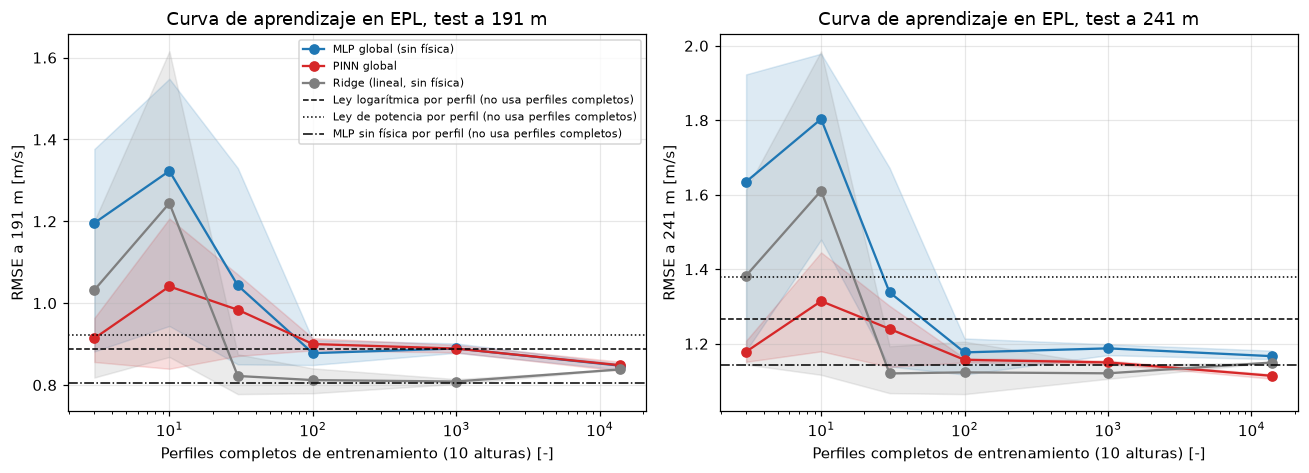

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True)
colores = {"MLP global (sin física)": "tab:blue", "PINN global": "tab:red", "Ridge (lineal, sin física)": "tab:gray"}
for a_, (h, j) in zip(ax, [(191, j191), (241, j241)]):
    for m, v in curva.items():
        r = v[:, :, j]
        a_.plot(TAM_EPL, r.mean(1), "o-", color=colores[m], label=m)
        a_.fill_between(TAM_EPL, r.min(1), r.max(1), color=colores[m], alpha=0.15)
    for m, ls in [("Ley logarítmica", "--"), ("Ley de potencia", ":"), ("MLP sin física", "-.")]:
        a_.axhline(rmse.loc[m, h], color="k", ls=ls, lw=1, label=f"{m} por perfil (no usa perfiles completos)")
    a_.set_xscale("log"); a_.set_xlabel("Perfiles completos de entrenamiento (10 alturas) [-]")
    a_.set_ylabel(f"RMSE a {h} m [m/s]"); a_.set_title(f"Curva de aprendizaje en EPL, test a {h} m")
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Lectura.**

- **Con pocos perfiles completos gana la PINN, y con claridad.** Con 3 perfiles, la PINN global tiene un RMSE de unos 0,91 m/s a 191 m y 1,18 m/s a 241 m, frente a 1,20 y 1,64 m/s del MLP global y 1,03 y 1,38 m/s del Ridge: entre un 11 y un 28 % menos. Además es **mucho más estable**: su desviación entre repeticiones es entre cinco y catorce veces menor. Con tres ejemplos, el MLP aprende lo que tienen de particular esos tres perfiles; la física le impide a la PINN inventar formas raras.
- **Con muchos perfiles, el MLP la alcanza.** A partir de unos 100 perfiles completos, MLP y PINN quedan prácticamente empatados a 191 m (0,85 m/s con todos). A 241 m la PINN conserva una ventaja pequeña (1,11 frente a 1,17 m/s, un 4 %), que en otros sitios no se repite (sección 16).
- **Entre 10 y 30 perfiles** todos los modelos son inestables y el Ridge, con sólo 5 coeficientes, es el mejor desde 30 perfiles. Un modelo sencillo con pocos datos es difícil de batir.
- **Cuidado con la comparación completa:** con 3 perfiles la PINN global queda ligeramente por detrás de la ley logarítmica por perfil a 191 m (0,91 frente a 0,89 m/s) y la mejora a 241 m (1,18 frente a 1,27 m/s). El MLP por perfil de la sección 10 sigue siendo el mejor a 191 m en EPL (0,80 m/s) por el aplanamiento afortunado que ya comentamos.


## 16. Física bien o mal especificada: mar abierto, costa y colina

Repetimos en los otros tres sitios los dos tipos de experimento, con los mismos criterios:

1. **Ajuste por perfil** (secciones 9 y 12): tres alturas bajas, sin ruido y con ruido gaussiano de 0,3 m/s, en 100 perfiles de test por sitio. Para EPL usamos los resultados de la sección 12 (400 perfiles). Métrica: RMSE medio en todas las alturas de test.
2. **Curva de aprendizaje** de los modelos globales con 3, 30, 300 y todos los perfiles completos (en EPL, 3, 30, 1000 y todos, de la sección 15).

Tarda unos 4 minutos.

In [23]:
# Mismo experimento por perfil de las secciones 9 y 12 en los otros tres sitios: 3 alturas, sin ruido y con ruido 0,3 m/s
t = time.time()
res_sitios = {}
for nombre, s in SITIOS.items():
    if nombre.startswith("EPL"):
        continue                                    # EPL ya está calculado en la sección 12 (400 perfiles)
    Vtr, Vte = s["Vt_tr"][:N_PP], s["Vt_te"][:N_PP]
    ruido_s = np.random.default_rng(SEMILLA).normal(0, 0.3, Vtr.shape)
    for etiqueta, Vn in [("sin ruido", Vtr), ("ruido 0,3", Vtr + ruido_s)]:
        P = {"Ley de potencia": ley_potencia(Vn, s["z_tr"], s["z_te"]), "Ley logarítmica": ley_log(Vn, s["z_tr"], s["z_te"]),
             "MLP sin física": entrenar(Vn, s["z_tr"], s["z_te"], lam=0.0)[0],
             "PINN-A (completa)": entrenar(Vn, s["z_tr"], s["z_te"], lam=1.0, contorno=True)[0],
             "PINN-B (sólo forma)": entrenar(Vn, s["z_tr"], s["z_te"], lam=1.0, contorno=False)[0]}
        res_sitios[(nombre, etiqueta)] = {m: np.sqrt(((p - Vte) ** 2).mean()) for m, p in P.items()}
for etiqueta, esc in [("sin ruido", "1) 3 niveles, sin ruido"), ("ruido 0,3", "2) 3 niveles, ruido 0,3")]:
    res_sitios[("EPL (mar, 50 km)", etiqueta)] = {m: np.sqrt((r ** 2).mean()) for m, r in res[esc].items()}
print(f"Tiempo: {time.time() - t:.0f} s")
tabla_pp = pd.DataFrame(res_sitios).T.sort_index(level=0, sort_remaining=False)
tabla_pp = tabla_pp.loc[[(n, e) for n in SITIOS for e in ["sin ruido", "ruido 0,3"]]]
print("RMSE [m/s] promediado en todas las alturas de test, ajuste por perfil con 3 alturas bajas")
display(tabla_pp.round(3))

Tiempo: 137 s
RMSE [m/s] promediado en todas las alturas de test, ajuste por perfil con 3 alturas bajas


Ley de potencia  Ley logarítmica  \
EPL (mar, 50 km)     sin ruido            0.950            0.892   
                     ruido 0,3            1.164            1.079   
K13A (mar, 100 km)   sin ruido            0.842            0.737   
                     ruido 0,3            1.051            0.953   
LEG (costa, 10 km)   sin ruido            0.635            0.610   
                     ruido 0,3            0.852            0.813   
Altahullion (colina) sin ruido            1.365            0.960   
                     ruido 0,3            1.603            1.079   

                                MLP sin física  PINN-A (completa)  \
EPL (mar, 50 km)     sin ruido           0.803              0.957   
                     ruido 0,3           1.205              1.049   
K13A (mar, 100 km)   sin ruido           0.583              0.755   
                     ruido 0,3           1.134              0.868   
LEG (costa, 10 km)   sin ruido           0.609              0.710   
                     ruido 0,3           0.980              0.776   
Altahullion (colina) sin ruido           1.044              1.590   
                     ruido 0,3           1.312              1.575   

                                PINN-B (sólo forma)  
EPL (mar, 50 km)     sin ruido                0.875  
                     ruido 0,3                1.026  
K13A (mar, 100 km)   sin ruido                0.720  
                     ruido 0,3                0.909  
LEG (costa, 10 km)   sin ruido                0.606  
                     ruido 0,3                0.699  
Altahullion (colina) sin ruido                0.969  
                     ruido 0,3                1.053

In [24]:
# Sensibilidad al peso de la física: K13A con ruido 0,3 m/s (misma realización de ruido que arriba)
t = time.time()
nombre = "K13A (mar, 100 km)"; s = SITIOS[nombre]
Vtr, Vte = s["Vt_tr"][:N_PP], s["Vt_te"][:N_PP]
Vn = Vtr + np.random.default_rng(SEMILLA).normal(0, 0.3, Vtr.shape)
sens = {m: {1.0: res_sitios[(nombre, "ruido 0,3")][m]} for m in ["PINN-A (completa)", "PINN-B (sólo forma)"]}
for lam in [0.1, 10.0]:
    for m, c in [("PINN-A (completa)", True), ("PINN-B (sólo forma)", False)]:
        sens[m][lam] = np.sqrt(((entrenar(Vn, s["z_tr"], s["z_te"], lam=lam, contorno=c)[0] - Vte) ** 2).mean())
tabla_lambda = pd.DataFrame(sens).T[[0.1, 1.0, 10.0]]
tabla_lambda.columns = [f"λ = {l}" for l in tabla_lambda.columns]
tabla_lambda.loc["mejor sin PINN (referencia)"] = min(res_sitios[(nombre, "ruido 0,3")][m] for m in ["Ley de potencia", "Ley logarítmica", "MLP sin física"])
print(f"Tiempo: {time.time() - t:.0f} s  |  RMSE [m/s] medio en las alturas de test, K13A con ruido 0,3 m/s")
display(tabla_lambda.round(3))

Tiempo: 44 s  |  RMSE [m/s] medio en las alturas de test, K13A con ruido 0,3 m/s


,λ = 0.1,λ = 1.0,λ = 10.0
PINN-A (completa),1.251,0.868,1.161
PINN-B (sólo forma),0.918,0.909,0.899
mejor sin PINN (referencia),0.953,0.953,0.953


In [25]:
# Curva de aprendizaje (modelos globales) en los otros tres sitios: 3, 30, 300 y todos los perfiles completos
t = time.time()
TAM_S = [3, 30, 300, None]
curvas_sitio = {}
for nombre, s in SITIOS.items():
    if nombre.startswith("EPL"):
        sel = [TAM_EPL.index(n) for n in [3, 30, 1000]] + [len(TAM_EPL) - 1]
        curvas_sitio[nombre] = {m: np.sqrt((curva[m][sel] ** 2).mean(-1)) for m in ["MLP global (sin física)", "PINN global"]}
        continue
    tam = [n or len(s["Vp_tr"]) for n in TAM_S]
    subs_s = subconjuntos_para(s, tam, REPS)
    out = {}
    for m, lam in [("MLP global (sin física)", 0.0), ("PINN global", 1.0)]:
        P, modelo, fis = entrenar_global(s, subs_s, lam=lam)
        out[m] = np.sqrt((rmse_alturas(P, s["Vt_te"]) ** 2).mean(-1)).reshape(len(tam), REPS)
        s[f"modelo {m}"], s[f"fis {m}"] = modelo, fis
    curvas_sitio[nombre] = out
print(f"Tiempo: {time.time() - t:.0f} s")
filas = []
for nombre, cv in curvas_sitio.items():
    for i, etiqueta in enumerate(["3", "30", "300 (EPL: 1000)", "todos"]):
        filas.append({"sitio": nombre, "perfiles completos": etiqueta,
                      "MLP global": cv["MLP global (sin física)"][i].mean(), "PINN global": cv["PINN global"][i].mean(),
                      "PINN - MLP": (cv["PINN global"][i] - cv["MLP global (sin física)"][i]).mean(),
                      "repeticiones en que gana la PINN": f"{(cv['PINN global'][i] < cv['MLP global (sin física)'][i]).sum()}/{REPS}"})
tabla_curvas_sitio = pd.DataFrame(filas).set_index(["sitio", "perfiles completos"])
print("RMSE [m/s] promediado en las alturas de test (media de 3 repeticiones)")
display(tabla_curvas_sitio.round(3))

Tiempo: 75 s
RMSE [m/s] promediado en las alturas de test (media de 3 repeticiones)


MLP global  PINN global  PINN - MLP  \
sitio                perfiles completos                                        
EPL (mar, 50 km)     3                        1.179        0.879      -0.301   
                     30                       1.004        0.941      -0.063   
                     300 (EPL: 1000)          0.860        0.852      -0.009   
                     todos                    0.831        0.816      -0.015   
K13A (mar, 100 km)   3                        0.806        0.755      -0.051   
                     30                       0.618        0.640       0.022   
                     300 (EPL: 1000)          0.628        0.640       0.012   
                     todos                    0.579        0.615       0.036   
LEG (costa, 10 km)   3                        0.680        0.650      -0.031   
                     30                       0.640        0.605      -0.036   
                     300 (EPL: 1000)          0.524        0.526       0.002   
                     todos                    0.510        0.532       0.022   
Altahullion (colina) 3                        1.129        0.984      -0.146   
                     30                       0.825        0.815      -0.010   
                     300 (EPL: 1000)          0.750        0.756       0.006   
                     todos                    0.749        0.751       0.002   

                                        repeticiones en que gana la PINN  
sitio                perfiles completos                                   
EPL (mar, 50 km)     3                                               3/3  
                     30                                              1/3  
                     300 (EPL: 1000)                                 2/3  
                     todos                                           3/3  
K13A (mar, 100 km)   3                                               3/3  
                     30                                              0/3  
                     300 (EPL: 1000)                                 0/3  
                     todos                                           0/3  
LEG (costa, 10 km)   3                                               2/3  
                     30                                              2/3  
                     300 (EPL: 1000)                                 2/3  
                     todos                                           0/3  
Altahullion (colina) 3                                               3/3  
                     30                                              2/3  
                     300 (EPL: 1000)                                 1/3  
                     todos                                           1/3

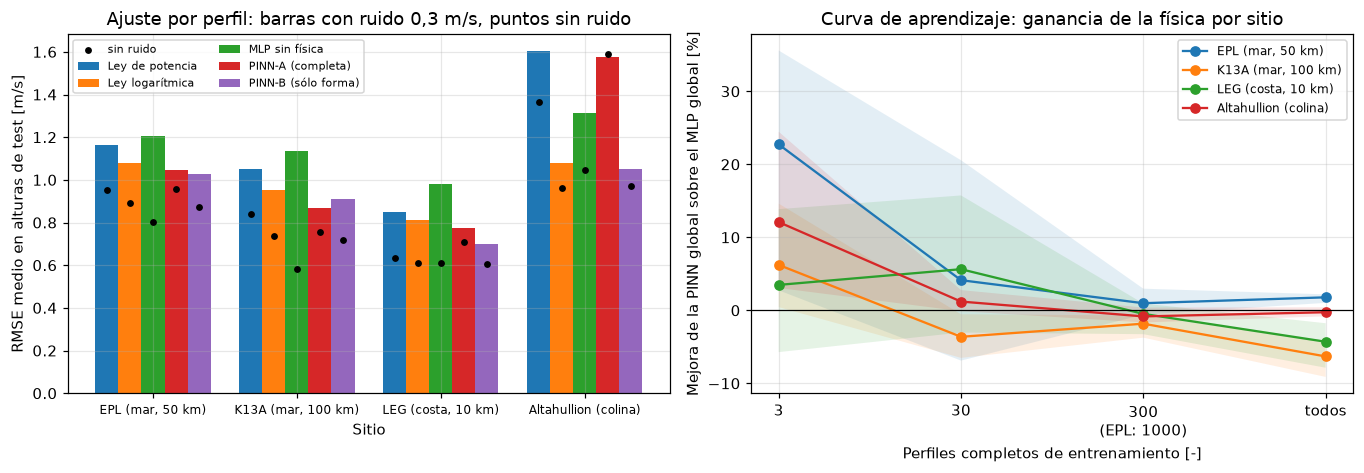

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
nombres = list(SITIOS); x = np.arange(len(nombres)); w = 0.16
metodos_pp = ["Ley de potencia", "Ley logarítmica", "MLP sin física", "PINN-A (completa)", "PINN-B (sólo forma)"]
for k, m in enumerate(metodos_pp):
    ax[0].bar(x + (k - 2) * w, [tabla_pp.loc[(n, "ruido 0,3"), m] for n in nombres], w, label=m)
    ax[0].scatter(x + (k - 2) * w, [tabla_pp.loc[(n, "sin ruido"), m] for n in nombres], color="k", s=12, zorder=3,
                  label="sin ruido" if k == 0 else None)
ax[0].set_xticks(x, nombres, fontsize=8); ax[0].set_ylabel("RMSE medio en alturas de test [m/s]")
ax[0].set_xlabel("Sitio"); ax[0].set_title("Ajuste por perfil: barras con ruido 0,3 m/s, puntos sin ruido"); ax[0].legend(fontsize=7, ncol=2)
for nombre in nombres:
    cv = curvas_sitio[nombre]
    ganancia = 100 * (cv["MLP global (sin física)"] - cv["PINN global"]) / cv["MLP global (sin física)"]
    ax[1].plot(range(4), ganancia.mean(1), "o-", label=nombre)
    ax[1].fill_between(range(4), ganancia.min(1), ganancia.max(1), alpha=0.12)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xticks(range(4), ["3", "30", "300\n(EPL: 1000)", "todos"])
ax[1].set_xlabel("Perfiles completos de entrenamiento [-]"); ax[1].set_ylabel("Mejora de la PINN global sobre el MLP global [%]")
ax[1].set_title("Curva de aprendizaje: ganancia de la física por sitio"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura: dónde gana la PINN y dónde no.**

*Ajuste por perfil.*

- **Sin ruido, la PINN no gana en ningún sitio.** En K13A el MLP es claramente el mejor (0,58 frente a 0,72 m/s de la PINN-B); en LEG y en la colina, la PINN-B empata con la ley logarítmica.
- **Con ruido, la PINN gana en el mar y empata en la colina.** En EPL la PINN-B baja el RMSE de 1,08 m/s (ley logarítmica) a 1,03 m/s (un 5 %); en K13A la PINN-A baja el RMSE de 0,95 m/s (ley logarítmica, la mejor sin PINN) a 0,87 m/s (un 9 %); en LEG la PINN-B lo baja de 0,81 a 0,70 m/s (un 14 %). En Altahullion la PINN-B queda a la par de la ley logarítmica (1,05 frente a 1,08 m/s).
- **La física mal especificada se paga caro.** En la colina, la PINN-A, que impone MO desde la superficie con la rugosidad del mar (Charnock), es con diferencia el peor método: 1,59 m/s sin ruido frente a 0,96 de la ley logarítmica, un 65 % peor. La PINN-B, que sólo impone la *forma* de MO entre 40 y 320 m, sobrevive porque exige menos. **Cuanta más física se impone, más se gana si es correcta y más se pierde si no lo es.**
- **El peso de la física ($\lambda$) importa, sobre todo si la física es fuerte.** En K13A con ruido, la PINN-A sólo gana con $\lambda=1$ (0,87 m/s); con $\lambda=0{,}1$ o $\lambda=10$ sube a 1,25 y 1,16 m/s, peor que la ley logarítmica (0,95). La PINN-B apenas cambia (0,90 a 0,92 m/s). No hicimos un barrido de $\lambda$ por sitio: en un proyecto real habría que elegirlo con validación cruzada, lo que encarece la PINN.

*Curva de aprendizaje (modelos globales).*

- **Con 3 perfiles completos, la PINN global gana en los cuatro sitios**: un 25 % en EPL, un 13 % en la colina, un 6 % en K13A y un 5 % en LEG, en casi todas las repeticiones.
- **Con todos los perfiles, el MLP empata o gana**: es un 6 % mejor en K13A y un 4 % en LEG; en EPL y en la colina quedan empatados. En la colina el empate llega antes de lo que cabría esperar: con datos abundantes, la red de la PINN absorbe lo que MO no explica y el residuo de la física pesa poco.


## 17. Extrapolación lejos del rango medido

Dos casos extremos, por perfil, en 100 perfiles de test:

1. **Hacia arriba, muy lejos**: medir sólo a 63 y 91 m y predecir hasta 291 m (más de tres veces la última medida).
2. **Hacia abajo, hacia la superficie**: medir en el rango alto y predecir por debajo. Aquí el MLP **no tiene ninguna información** (no hay datos por debajo y su forma se aplana), mientras que la PINN-A conoce una condición física: $V(z_0)=0$ en la superficie, con $z_0$ diminuta. Lo hacemos en EPL (medir 141 a 241 m, predecir 63 a 116 m) y en la colina (medir 68 a 203 m, predecir 18 a 58 m), donde esa condición es más dudosa.

In [27]:
# Extrapolación lejos del rango medido, en los mismos 100 perfiles de test de cada sitio
t = time.time()
casos = {
    "EPL hacia arriba: mide 63-91, predice 141-291": ("EPL (mar, 50 km)", [63, 91], [141, 166, 191, 216, 241, 266, 291]),
    "EPL hacia abajo: mide 141-241, predice 63-116": ("EPL (mar, 50 km)", [141, 166, 191, 216, 241], [63, 91, 116]),
    "Altahullion hacia abajo: mide 68-203, predice 18-58": ("Altahullion (colina)", [68, 78, 88, 98, 141, 203], [18, 28, 38, 48, 58]),
}
res_extra = {}
for caso, (nombre, zm, zp) in casos.items():
    tst = SITIOS[nombre]["test"].iloc[:N_PP]
    Vm, Vp = tst[[f"ws_{h}" for h in zm]].values, tst[[f"ws_{h}" for h in zp]].values
    zm, zp = np.array(zm, float), np.array(zp, float)
    P = {"Ley de potencia": ley_potencia(Vm, zm, zp), "Ley logarítmica": ley_log(Vm, zm, zp),
         "MLP sin física": entrenar(Vm, zm, zp, lam=0.0)[0],
         "PINN-A (completa)": entrenar(Vm, zm, zp, lam=1.0, contorno=True)[0],
         "PINN-B (sólo forma)": entrenar(Vm, zm, zp, lam=1.0, contorno=False)[0]}
    res_extra[caso] = (zp, {m: rmse_alturas(p, Vp) for m, p in P.items()}, {m: (p - Vp).mean(0) for m, p in P.items()})
print(f"Tiempo: {time.time() - t:.0f} s")
for caso, (zp, r, b) in res_extra.items():
    print(caso)
    display(pd.DataFrame(r, index=pd.Index(zp.astype(int), name="altura [m]")).T.round(3))

Tiempo: 75 s
EPL hacia arriba: mide 63-91, predice 141-291


altura [m],141,166,191,216,241,266,291
Ley de potencia,0.684,1.096,1.527,1.783,1.987,2.173,2.345
Ley logarítmica,0.636,1.031,1.439,1.655,1.809,1.943,2.061
MLP sin física,0.635,1.029,1.444,1.663,1.812,1.940,2.046
PINN-A (completa),0.667,1.091,1.492,1.694,1.810,1.923,2.022
PINN-B (sólo forma),0.635,1.029,1.431,1.639,1.777,1.897,2.001


EPL hacia abajo: mide 141-241, predice 63-116


altura [m],63,91,116
Ley de potencia,1.789,0.932,0.452
Ley logarítmica,1.979,1.084,0.526
MLP sin física,2.408,1.444,0.566
PINN-A (completa),1.097,0.817,0.498
PINN-B (sólo forma),1.739,1.086,0.662


Altahullion hacia abajo: mide 68-203, predice 18-58


altura [m],18,28,38,48,58
Ley de potencia,1.723,1.100,0.722,0.576,0.432
Ley logarítmica,3.407,2.061,1.202,0.761,0.476
MLP sin física,3.184,2.232,1.441,0.789,0.314
PINN-A (completa),0.731,0.609,0.705,0.674,0.554
PINN-B (sólo forma),3.577,2.241,1.293,0.764,0.438


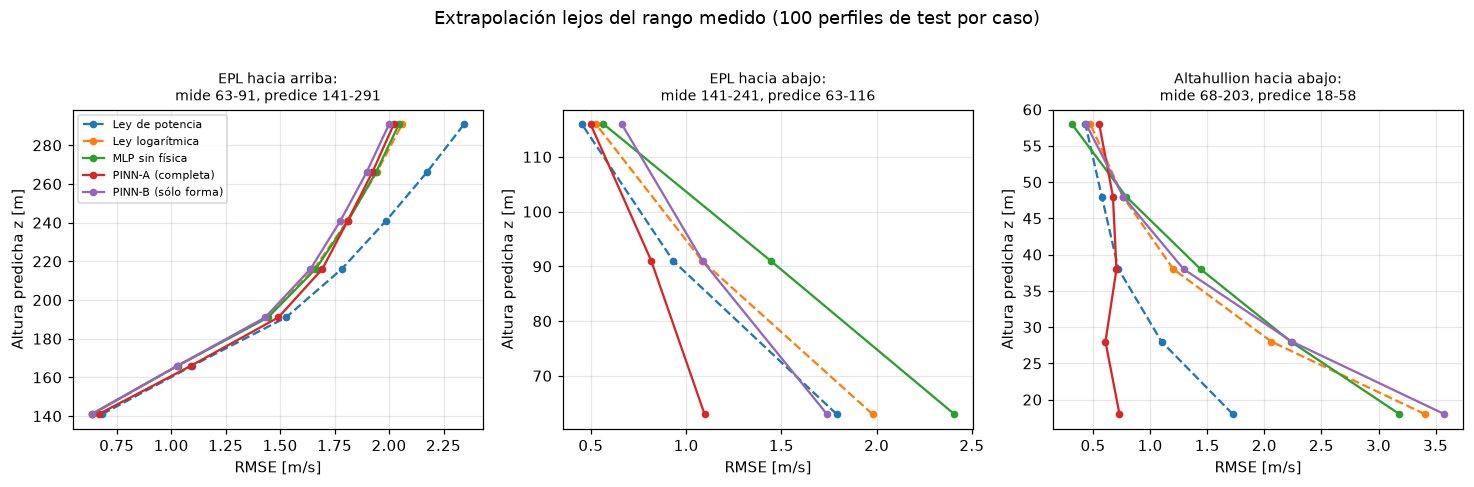

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.3))
for a_, (caso, (zp, r, b)) in zip(ax, res_extra.items()):
    for m, v in r.items():
        a_.plot(v, zp, "--" if m.startswith("Ley") else "-", marker="o", ms=4, label=m)
    a_.set_xlabel("RMSE [m/s]"); a_.set_ylabel("Altura predicha z [m]")
    a_.set_title(caso.replace(": ", ":\n"), fontsize=9)
ax[0].legend(fontsize=7)
plt.suptitle("Extrapolación lejos del rango medido (100 perfiles de test por caso)", y=1.02)
plt.tight_layout(); plt.show()

**Lectura.**

- **Hacia arriba, la física no rescata la falta de información.** Con dos alturas, la PINN-B es la mejor por encima de 191 m, pero por muy poco: 2,00 m/s a 291 m frente a 2,05 del MLP y 2,06 de la ley logarítmica (2 a 3 %). Todos los métodos se equivocan unos 2 m/s: lo que pasa a 290 m no está en dos medidas por debajo de 100 m.
- **Hacia abajo, la condición de contorno marca la diferencia.** En EPL, a 63 m la PINN-A tiene un RMSE de 1,10 m/s, frente a 1,79 de la ley de potencia (la mejor sin PINN) y 2,41 del MLP: un 39 % menos. La PINN-B, que no tiene la condición $V(z_0)=0$, no mejora nada (1,74 m/s): **la ganancia viene de la condición de contorno, no de la red**.
- **En la colina también ocurre**, cerca del suelo: a 18 m la PINN-A baja de 1,72 m/s (ley de potencia) a 0,73 m/s. Aunque el valor de $z_0$ marino es incorrecto en tierra, cualquier $z_0$ mucho menor que 18 m obliga a un descenso logarítmico hacia cero, que es lo que falta a las demás. Pero a 48 y 58 m, cerca del rango medido, el MLP y la ley de potencia son mejores (0,31 frente a 0,55 m/s a 58 m): la condición en la superficie distorsiona el perfil donde ya había datos cerca.
- Regla: **la física ayuda a extrapolar cuando aporta una condición que los datos no contienen** (el suelo). No ayuda a extrapolar hacia arriba, donde la teoría de capa superficial ya no vale.


## 18. Inversión: cuando lo que se busca es el parámetro físico

A veces el objetivo no es la velocidad sino un **parámetro físico**: la velocidad de fricción $u_*$ (para cargas o turbulencia) o la longitud de Obukhov $L$ (estabilidad). Un MLP no puede darlos; la PINN los aprende como parámetros. Pero un ajuste clásico de MO por mínimos cuadrados también los da, así que la comparación justa es con él.

Comparamos, con las tres alturas bajas de 100 perfiles de EPL, sin ruido y con ruido fuerte (0,5 m/s):

- **Ley logarítmica**: $u_* = \kappa \times$ pendiente (no da $L$).
- **MO + Charnock por mínimos cuadrados**: ajuste no lineal de $u_*$ y $1/L$ con $z_0$ de Charnock.
- **PINN-A**: $u_*$ y $1/L$ aprendidos (con la misma relación de Charnock como ligadura suave).

**Qué es verdad y qué no.** En datos reales no tenemos flujos turbulentos medidos. Usamos como **referencia aproximada** el ajuste de MO + Charnock a las **10 alturas limpias** del mismo perfil (63 a 291 m), y sólo en los perfiles donde ese ajuste tiene un error menor de 0,2 m/s. No es una medida: es otro ajuste, con el mismo modelo que el método de mínimos cuadrados, lo que favorece a ese método sin ruido. Por eso añadimos un **control con verdad conocida**: 100 perfiles generados con MO + Charnock, con $u_*$ y $L$ conocidos, en las mismas alturas.

In [29]:
# Inversión: estimar u* y 1/L con las 3 alturas bajas (63-116 m), sin ruido y con ruido fuerte (0,5 m/s)
t = time.time()
Vtr, tst = V_tr[:N_PP], test.iloc[:N_PP]
Vfull = tst[COLS].values
# Referencia aproximada: ajuste de MO con Charnock a las 10 alturas limpias (63-291 m) del mismo perfil
ajustes = [ajuste_mo(np.array(ALTURAS, float), v) for v in Vfull]
ref, err_ref = np.array([a_[0] for a_ in ajustes]), np.array([a_[1] for a_ in ajustes])
fiable = err_ref < 0.2                          # sólo perfiles que MO describe razonablemente bien

def resumen_inversion(ust, invL, ust_ref, invL_ref, m):
    rel = np.abs(ust[m] - ust_ref[m]) / ust_ref[m]
    if invL is None:                             # la ley log no estima estabilidad
        invL = np.full_like(ust, np.nan)
    return {"error relativo u*, mediana [%]": 100 * np.median(rel),
            "u* fuera de [0,05; 1,5] m/s [%]": 100 * np.mean((ust[m] < 0.05) | (ust[m] > 1.5)),
            "acierto signo de 1/L [%]": np.nan if np.isnan(invL).all() else 100 * np.mean(np.sign(invL[m]) == np.sign(invL_ref[m])),
            "correlación de rangos 1/L": pd.Series(invL[m]).corr(pd.Series(invL_ref[m]), method="spearman")}

filas = {}
for sigma in [0.0, 0.5]:
    Vn = Vtr + np.random.default_rng(SEMILLA + 1).normal(0, sigma, Vtr.shape)
    a, b = ajuste_recta(np.log(Z_TR), Vn)
    lsq = np.array([ajuste_mo(Z_TR, v)[0] for v in Vn])
    _, fA = entrenar(Vn, Z_TR, Z_TE, lam=1.0, contorno=True)
    est = {"Ley log (pendiente)": (KAPPA * b, None), "MO + Charnock, mínimos cuadrados": (lsq[:, 0], lsq[:, 1]),
           "PINN-A": (fA["u*"], fA["1/L"])}
    for metodo, (u, il_) in est.items():
        filas[(f"ruido {sigma}", metodo)] = resumen_inversion(u, il_, ref[:, 0], ref[:, 1], fiable)
print(f"Perfiles con referencia fiable: {fiable.sum()} de {N_PP}  |  Tiempo: {time.time() - t:.0f} s")
tabla_inv = pd.DataFrame(filas).T
display(tabla_inv.round(2))

Perfiles con referencia fiable: 55 de 100  |  Tiempo: 33 s


error relativo u*, mediana [%]  \
ruido 0.0 Ley log (pendiente)                                        65.30   
          MO + Charnock, mínimos cuadrados                            3.82   
          PINN-A                                                     11.64   
ruido 0.5 Ley log (pendiente)                                       104.86   
          MO + Charnock, mínimos cuadrados                           15.45   
          PINN-A                                                      8.55   

                                            u* fuera de [0,05; 1,5] m/s [%]  \
ruido 0.0 Ley log (pendiente)                                         23.64   
          MO + Charnock, mínimos cuadrados                             0.00   
          PINN-A                                                       0.00   
ruido 0.5 Ley log (pendiente)                                         45.45   
          MO + Charnock, mínimos cuadrados                             0.00   
          PINN-A                                                       0.00   

                                            acierto signo de 1/L [%]  \
ruido 0.0 Ley log (pendiente)                                    NaN   
          MO + Charnock, mínimos cuadrados                     83.64   
          PINN-A                                               54.55   
ruido 0.5 Ley log (pendiente)                                    NaN   
          MO + Charnock, mínimos cuadrados                     58.18   
          PINN-A                                               43.64   

                                            correlación de rangos 1/L  
ruido 0.0 Ley log (pendiente)                                     NaN  
          MO + Charnock, mínimos cuadrados                       0.70  
          PINN-A                                                 0.25  
ruido 0.5 Ley log (pendiente)                                     NaN  
          MO + Charnock, mínimos cuadrados                      -0.05  
          PINN-A                                                 0.06

In [30]:
# Control con verdad conocida: perfiles de MO + Charnock generados con u* y 1/L conocidos, en las mismas alturas
rng_s = np.random.default_rng(SEMILLA + 2)
n_s = N_PP
ust_v = rng_s.uniform(0.15, 0.6, n_s)
invL_v = rng_s.uniform(-0.01, 0.004, n_s)              # inestable |L| > 100 m, estable L > 250 m
V_sint = perfil_mo(Z_TR[None], ust_v[:, None], invL_v[:, None])
filas = {}
for sigma in [0.0, 0.5]:
    Vn = V_sint + rng_s.normal(0, sigma, V_sint.shape)
    a, b = ajuste_recta(np.log(Z_TR), Vn)
    lsq = np.array([ajuste_mo(Z_TR, v)[0] for v in Vn])
    _, fA = entrenar(Vn, Z_TR, Z_TE, lam=1.0, contorno=True)
    est = {"Ley log (pendiente)": (KAPPA * b, None), "MO + Charnock, mínimos cuadrados": (lsq[:, 0], lsq[:, 1]),
           "PINN-A": (fA["u*"], fA["1/L"])}
    for metodo, (u, il_) in est.items():
        filas[(f"ruido {sigma}", metodo)] = resumen_inversion(u, il_, ust_v, invL_v, np.ones(n_s, bool))
tabla_inv_sint = pd.DataFrame(filas).T
display(tabla_inv_sint.round(2))

error relativo u*, mediana [%]  \
ruido 0.0 Ley log (pendiente)                                        43.47   
          MO + Charnock, mínimos cuadrados                            0.00   
          PINN-A                                                     11.94   
ruido 0.5 Ley log (pendiente)                                       100.85   
          MO + Charnock, mínimos cuadrados                           13.12   
          PINN-A                                                      8.61   

                                            u* fuera de [0,05; 1,5] m/s [%]  \
ruido 0.0 Ley log (pendiente)                                           0.0   
          MO + Charnock, mínimos cuadrados                              0.0   
          PINN-A                                                        0.0   
ruido 0.5 Ley log (pendiente)                                          32.0   
          MO + Charnock, mínimos cuadrados                              0.0   
          PINN-A                                                        0.0   

                                            acierto signo de 1/L [%]  \
ruido 0.0 Ley log (pendiente)                                    NaN   
          MO + Charnock, mínimos cuadrados                     100.0   
          PINN-A                                                31.0   
ruido 0.5 Ley log (pendiente)                                    NaN   
          MO + Charnock, mínimos cuadrados                      59.0   
          PINN-A                                                46.0   

                                            correlación de rangos 1/L  
ruido 0.0 Ley log (pendiente)                                     NaN  
          MO + Charnock, mínimos cuadrados                       1.00  
          PINN-A                                                -0.52  
ruido 0.5 Ley log (pendiente)                                     NaN  
          MO + Charnock, mínimos cuadrados                       0.26  
          PINN-A                                                 0.12

**Lectura.**

- **La ley logarítmica no sirve para estimar $u_*$** a 60 a 120 m: error mediano de 65 % sin ruido y de 100 % con ruido, con hasta un 45 % de valores imposibles. El perfil a esas alturas no es neutro.
- **Sin ruido, el ajuste clásico gana.** Con datos reales, error de 4 % frente a 12 % de la PINN-A (con la ventaja de compartir modelo con la referencia); con verdad conocida, el ajuste clásico recupera exactamente los parámetros y la PINN-A se queda en un 12 %. Si el modelo es exacto y los datos limpios, no hace falta una red.
- **Con ruido fuerte, la PINN estima mejor $u_*$**: 8,6 % frente a 15 % del ajuste clásico con datos reales, y 8,6 % frente a 13 % con verdad conocida. La red absorbe parte del ruido y la ligadura de Charnock estabiliza $u_*$.
- **Nadie recupera bien la estabilidad con tres alturas ruidosas.** El acierto del signo de $1/L$ queda entre el 44 y el 59 % (el azar es 50 %). Y la PINN-A tampoco identifica $L$ sin ruido: con verdad conocida acierta el signo sólo en el 31 % de los perfiles. La red es tan flexible que puede curvar el perfil por su cuenta y deja $L$ mal determinada. **La PINN da un $u_*$ útil con datos ruidosos, pero no una $L$ fiable.**


## 19. Transferencia entre sitios

¿Sirve un modelo entrenado en un sitio con muchos datos para otro sitio con pocos? Entrenamos el MLP global y la PINN global con **todos** los perfiles de EPL (sección 15) y los aplicamos a los otros tres sitios:

- **sin ajuste** (0 perfiles del destino);
- con **ajuste fino** de 500 pasos usando 3 o 30 perfiles completos del destino (más sus alturas bajas y, en la PINN, el residuo de MO);
- frente a entrenar **desde cero** en el destino con esos mismos perfiles (sección 16).

Como las entradas son alturas relativas y cocientes de velocidad, la misma red se puede aplicar en sitios con alturas distintas.

Después miramos **qué parámetros físicos se transfieren**: comparamos el $u_*/V(z_{top})$ y el $1/L$ que la red de parámetros de EPL infiere en cada destino con los que infiere una PINN entrenada con todos los datos del propio destino.

In [31]:
# Transferencia: modelos globales entrenados con TODOS los perfiles de EPL, aplicados a otro sitio
# (a) tal cual, sin ajuste; (b) con ajuste fino usando 3 o 30 perfiles completos del sitio destino
t = time.time()
k_todos = len(subs) - REPS                          # índice de la primera red EPL entrenada con todos los perfiles
res_trans, fis_trans = {}, {}
for nombre, s in SITIOS.items():
    if nombre.startswith("EPL"):
        continue
    subs_t = subconjuntos_para(s, [3, 30], REPS)
    for m, lam, modelo in [("MLP global (sin física)", 0.0, mod_mlp_epl), ("PINN global", 1.0, mod_pinn_epl)]:
        red_o, par_o = modelo
        P0, _, f0 = entrenar_global(s, subs_t[:1], lam=lam, pasos=0, inicio=((red_o, k_todos), (par_o, k_todos)))
        Pf, _, _ = entrenar_global(s, subs_t, lam=lam, pasos=500, inicio=((red_o, k_todos), (par_o, k_todos)))
        r0 = np.sqrt((rmse_alturas(P0, s["Vt_te"]) ** 2).mean(-1))[0]
        rf = np.sqrt((rmse_alturas(Pf, s["Vt_te"]) ** 2).mean(-1)).reshape(2, REPS).mean(1)
        rc = curvas_sitio[nombre][m][:2].mean(1)                 # desde cero (sección 15), 3 y 30 perfiles
        res_trans[(nombre, m)] = {"sin ajuste (0 perfiles)": r0, "ajuste fino, 3": rf[0], "desde cero, 3": rc[0],
                                  "ajuste fino, 30": rf[1], "desde cero, 30": rc[1]}
        if lam > 0:
            fis_trans[nombre] = f0
print(f"Tiempo: {time.time() - t:.0f} s")
print("RMSE [m/s] promediado en las alturas de test del sitio destino (origen: EPL)")
display(pd.DataFrame(res_trans).T.round(3))

# ¿Qué parámetros físicos se transfieren? Comparamos lo que infiere en el destino la red de parámetros de EPL
# con lo que infiere una PINN entrenada con todos los datos del propio destino. Usamos u*/V(z_top), no u*,
# porque u* es proporcional a V(z_top) por construcción y eso inflaría la correlación
filas = {}
k_loc = len(TAM_S) * REPS - REPS
for nombre, f0 in fis_trans.items():
    fl, vtop = SITIOS[nombre]["fis PINN global"], SITIOS[nombre]["Vt_tr"][:, 2]
    a0, al = f0["u*"][0] / vtop, fl["u*"][k_loc] / vtop
    filas[nombre] = {"u*/V_top mediana, red de EPL [-]": np.median(a0), "u*/V_top mediana, red local [-]": np.median(al),
                     "correlación u*/V_top": np.corrcoef(a0, al)[0, 1],
                     "1/L mediana, red de EPL [1/km]": 1000 * np.median(f0["1/L"][0]),
                     "1/L mediana, red local [1/km]": 1000 * np.median(fl["1/L"][k_loc]),
                     "correlación 1/L": np.corrcoef(f0["1/L"][0], fl["1/L"][k_loc])[0, 1]}
display(pd.DataFrame(filas).T.round(3))

Tiempo: 39 s
RMSE [m/s] promediado en las alturas de test del sitio destino (origen: EPL)


sin ajuste (0 perfiles)  \
K13A (mar, 100 km)   MLP global (sin física)                    0.644   
                     PINN global                                0.635   
LEG (costa, 10 km)   MLP global (sin física)                    0.613   
                     PINN global                                0.575   
Altahullion (colina) MLP global (sin física)                    1.179   
                     PINN global                                1.279   

                                              ajuste fino, 3  desde cero, 3  \
K13A (mar, 100 km)   MLP global (sin física)           0.765          0.806   
                     PINN global                       0.721          0.755   
LEG (costa, 10 km)   MLP global (sin física)           0.593          0.680   
                     PINN global                       0.551          0.650   
Altahullion (colina) MLP global (sin física)           1.157          1.129   
                     PINN global                       0.958          0.984   

                                              ajuste fino, 30  desde cero, 30  
K13A (mar, 100 km)   MLP global (sin física)            0.625           0.618  
                     PINN global                        0.611           0.640  
LEG (costa, 10 km)   MLP global (sin física)            0.638           0.640  
                     PINN global                        0.555           0.605  
Altahullion (colina) MLP global (sin física)            0.813           0.825  
                     PINN global                        0.817           0.815

,"u*/V_top mediana, red de EPL [-]","u*/V_top mediana, red local [-]",correlación u*/V_top,"1/L mediana, red de EPL [1/km]","1/L mediana, red local [1/km]",correlación 1/L
"K13A (mar, 100 km)",0.039,0.041,0.990,-1.765,-1.299,0.721
"LEG (costa, 10 km)",0.026,0.023,0.996,-1.843,-0.573,0.735
Altahullion (colina),0.109,0.092,0.922,-1.220,0.409,-0.471


**Lectura.**

- **De mar a mar, el modelo transferido sin ajuste ya funciona**: en K13A y LEG la PINN de EPL sin ajuste (0,64 y 0,58 m/s) queda cerca de lo que se consigue con datos locales, y mejor que entrenar desde cero con 3 perfiles. La PINN transferida es algo mejor que el MLP transferido.
- **De mar a colina, no**: sin ajuste ambos modelos fallan (1,18 a 1,28 m/s frente a 0,75 con datos locales).
- **El ajuste fino con 3 perfiles es arriesgado.** En K13A empeora a ambos modelos respecto a no ajustar (sobreajuste a tres perfiles), aunque la PINN se degrada menos. En LEG y sobre todo en la colina, el ajuste fino de la PINN es lo mejor con 3 perfiles (0,96 frente a 1,16 m/s del MLP en la colina, un 17 % menos). Con 30 perfiles las diferencias desaparecen en K13A y en la colina, pero en LEG la PINN ajustada sigue siendo mejor (0,56 frente a 0,64 m/s).
- **Qué se transfiere.** La escala de fricción relativa $u_*/V(z_{top})$ se parece entre EPL y los sitios marinos (ver la tabla), pero la estabilidad $1/L$ se transfiere peor, y en la colina deja de tener sentido físico: la red local la usa para absorber el efecto del terreno. Lo que viaja bien entre sitios es la **forma** del perfil cuando la física es la misma; los parámetros de estabilidad son locales.


## 20. Mapa de decisión: cuándo usar una PINN y cuándo no

El mapa resume la **mejora relativa del RMSE de la PINN sobre la mejor alternativa sin PINN** en cada prueba de las secciones 12 y 15 a 19 (azul: gana la PINN; rojo: pierde). En las pruebas por perfil se compara la mejor de las dos PINN con el mejor de los tres métodos sin PINN; en las globales, PINN global frente a MLP global; en transferencia, ambos con ajuste fino de 3 perfiles. En las celdas de extrapolación la mejora se promedia sobre todas las alturas predichas, por eso es menor que en la altura más baja.

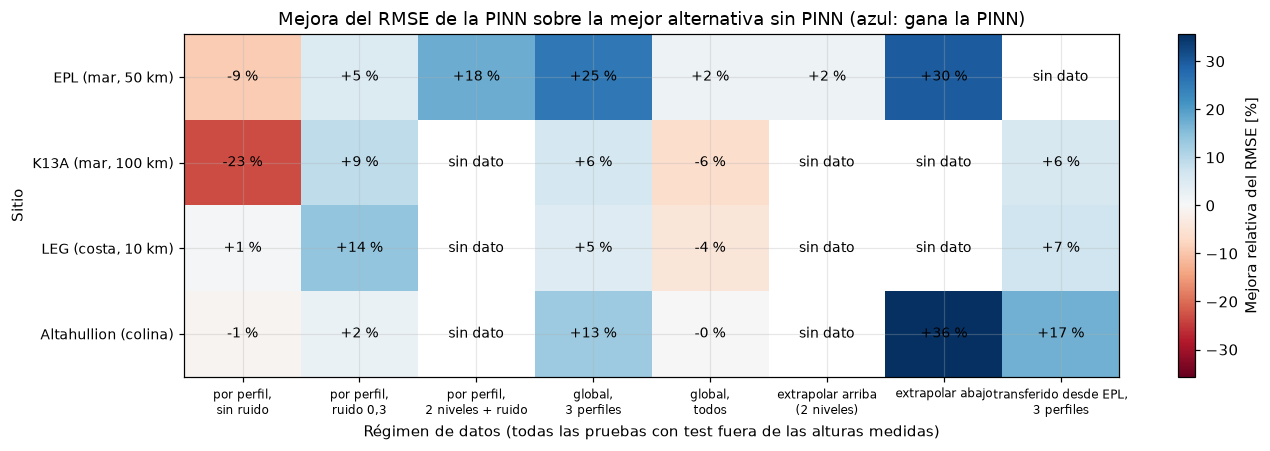

In [32]:
# Mapa de regímenes: mejora relativa de la PINN frente a la mejor alternativa sin PINN en cada prueba (mismos test)
def ganancia(r_pinn, r_alt):
    return 100 * (r_alt - r_pinn) / r_alt

regimenes = {}
sin_pinn = ["Ley de potencia", "Ley logarítmica", "MLP sin física"]
con_pinn = ["PINN-A (completa)", "PINN-B (sólo forma)"]
for (nombre, etiqueta), r in res_sitios.items():
    regimenes.setdefault(nombre, {})[f"por perfil, {etiqueta}"] = ganancia(min(r[m] for m in con_pinn), min(r[m] for m in sin_pinn))
regimenes["EPL (mar, 50 km)"]["por perfil, 2 niveles + ruido"] = ganancia(
    min(np.sqrt((res["4) 2 niveles, ruido 0,3"][m] ** 2).mean()) for m in con_pinn),
    min(np.sqrt((res["4) 2 niveles, ruido 0,3"][m] ** 2).mean()) for m in sin_pinn))
for nombre, cv in curvas_sitio.items():
    for i, etq in [(0, "global, 3 perfiles"), (3, "global, todos")]:
        regimenes[nombre][etq] = ganancia(cv["PINN global"][i].mean(), cv["MLP global (sin física)"][i].mean())
for caso, (zp, r, b) in res_extra.items():
    nombre = "EPL (mar, 50 km)" if caso.startswith("EPL") else "Altahullion (colina)"
    etq = "extrapolar arriba (2 niveles)" if "arriba" in caso else "extrapolar abajo"
    regimenes[nombre][etq] = ganancia(min(np.sqrt((r[m] ** 2).mean()) for m in con_pinn),
                                      min(np.sqrt((r[m] ** 2).mean()) for m in sin_pinn))
for (nombre, m), r in res_trans.items():
    if m == "PINN global":
        rm = res_trans[(nombre, "MLP global (sin física)")]
        regimenes[nombre]["transferido desde EPL, 3 perfiles"] = ganancia(r["ajuste fino, 3"], rm["ajuste fino, 3"])
mapa = pd.DataFrame(regimenes).T.loc[list(SITIOS)]
mapa = mapa[["por perfil, sin ruido", "por perfil, ruido 0,3", "por perfil, 2 niveles + ruido", "global, 3 perfiles",
             "global, todos", "extrapolar arriba (2 niveles)", "extrapolar abajo", "transferido desde EPL, 3 perfiles"]]

fig, ax = plt.subplots(figsize=(12.5, 4.2))
lim = np.nanmax(np.abs(mapa.values))
im = ax.imshow(mapa.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ax.text(j, i, "sin dato" if np.isnan(v) else f"{v:+.0f} %", ha="center", va="center", fontsize=9)
ax.set_xticks(range(mapa.shape[1]), [c.replace(", ", ",\n").replace(" (", "\n(") for c in mapa.columns], fontsize=8)
ax.set_yticks(range(mapa.shape[0]), mapa.index, fontsize=9)
ax.set_xlabel("Régimen de datos (todas las pruebas con test fuera de las alturas medidas)"); ax.set_ylabel("Sitio")
ax.set_title("Mejora del RMSE de la PINN sobre la mejor alternativa sin PINN (azul: gana la PINN)")
plt.colorbar(im, ax=ax, label="Mejora relativa del RMSE [%]")
plt.tight_layout(); plt.show()


### Tabla de decisión (basada en los números de este cuaderno)

| Situación | Qué hemos medido | ¿PINN? |
|---|---|---|
| **Pocos perfiles completos** para entrenar (unos 3 a 10) | PINN global mejor que el MLP global en los cuatro sitios (de 5 a 25 %) y mucho más estable entre repeticiones (secciones 15 y 16) | **Sí** |
| **Muchos perfiles completos** (cientos o miles) | empate o MLP mejor (MLP un 6 % mejor en K13A y un 4 % en LEG); el Ridge ya es competitivo desde 30 perfiles en EPL | **No hace falta** |
| **Medidas ruidosas** con pocas alturas | PINN entre un 5 y un 14 % mejor que la mejor alternativa en los tres sitios marinos; empate en la colina (secciones 12 y 16) | **Sí, si la física vale** |
| **Medidas limpias** con tres alturas, ajuste por perfil | MLP o ley logarítmica iguales o mejores en los cuatro sitios | **No** |
| **Extrapolar hacia la superficie** | PINN-A con $V(z_0)=0$ reduce el error a la altura más baja un 39 % en el mar y un 58 % en la colina; sin la condición de contorno no hay mejora (sección 17) | **Sí, con condición de contorno** |
| **Extrapolar muy por encima** de lo medido | mejora de un 2 a 3 %, todos los métodos fallan unos 2 m/s (sección 17) | **No resuelve el problema: hay que medir** |
| **Necesito $u_*$** y los datos son ruidosos | error de $u_*$ de 8,6 % frente a 13 a 15 % del ajuste clásico (sección 18) | **Sí** |
| **Necesito $L$** (estabilidad) | ningún método la recupera con tres alturas ruidosas; la PINN tampoco sin ruido (sección 18) | **No, mide flujos** |
| **Física mal especificada** (terreno complejo, estelas, capa estable baja) | imponer MO desde la superficie empeora un 65 % en la colina; imponer sólo la forma empata (sección 16) | **No impongas lo que no se cumple** |
| **Transferir** de un sitio con muchos datos a otro con pocos | mar a mar funciona sin ajuste; mar a colina no; con ajuste fino de 3 perfiles la PINN es entre un 6 y un 17 % mejor que el MLP, aunque en K13A ajustar con 3 perfiles empeora respecto a no ajustar (sección 19) | **Sí entre sitios parecidos** |
| **Coste y ajuste** | la PINN tarda unas dos veces más en entrenar (derivadas de segundo orden); la PINN-A sólo gana con $\lambda=1$ y empeora con 0,1 o 10, la PINN-B es estable (sección 16) | **Sólo si lo anterior compensa** |

**La regla práctica que sale de los datos:** una PINN merece la pena cuando **falta información** (pocos perfiles, ruido, una frontera sin medir) **y** la física que impones **se cumple donde la impones**. Si los datos son abundantes y limpios, un modelo estadístico basta; si la física no describe el sitio, añadirla empeora el resultado, y cuanto más fuerte sea la ligadura, más.


## 21. Qué te llevas, limitaciones y ejercicios


### Qué se lleva un alumno

1. **Una PINN es una red con una pérdida extra**: datos + residuo de una ecuación evaluado con diferenciación automática + condiciones de contorno, con parámetros físicos que se aprenden a la vez que los pesos.
2. **La física es un regularizador, no un oráculo.** Ayuda con datos escasos o ruidosos; si la ecuación no describe bien el rango de interés (MO por encima de la capa superficial), empeora el resultado.
3. **Evalúa siempre fuera de la muestra y frente a referencias simples** (persistencia, ley log). Sin ellas, cualquier método parece bueno.
4. **Mira el sesgo, no sólo el RMSE**: un sesgo de 0,2 m/s a la altura de buje puede suponer varios puntos de producción anual.
5. **Comprueba que los parámetros físicos se mueven.** Un gradiente nulo (como el de `clamp` en cero) deja una PINN que "entrena" sin aprender física.
6. **Cuándo sí y cuándo no (sección 20).** La PINN gana con pocos perfiles completos, con medidas ruidosas, al extrapolar hacia una frontera con condición física (el suelo) y para estimar $u_*$ con ruido. No gana con datos abundantes y limpios, al extrapolar muy por encima de lo medido, ni para estimar la estabilidad.
7. **La física mal especificada se paga.** En terreno complejo, imponer MO desde la superficie empeora mucho; imponer sólo la forma del perfil es más seguro. Mide primero cuánto se aleja tu sitio de la teoría (sección 14).


### Limitaciones

- **No es un modelo meteorológico (NWP).** No resuelve la dinámica de la capa límite, ni chorros de bajo nivel, ni la evolución temporal; extrapola un perfil instantáneo.
- **No sustituye a un lidar.** A 241 m todos los métodos, incluso uno entrenado con medidas altas de otros días (sección 13), se quedan en torno a 1,1 a 1,3 m/s de RMSE. Las medidas bajas no contienen la información que falta.
- **MO fuera de su rango.** La teoría vale en la capa superficial; a 150 a 250 m sobre el mar a menudo no se cumple.
- **Sin estabilidad medida.** Las clases son un indicador indirecto por cizalladura; no hay flujos de calor ni temperatura del mar en estos datos.
- **Pocos sitios y periodos cortos.** Las secciones 7 a 13 usan un único emplazamiento y un año, 400 perfiles de test y una realización del ruido; la ampliación (14 a 20) añade tres sitios, pero los experimentos por perfil usan sólo 100 perfiles por sitio y tres repeticiones. Las diferencias de pocos centímetros por segundo, o de menos de un 5 %, entre métodos no son significativas.
- **Sin verdad de referencia para los parámetros físicos** en los datos reales: en la sección 18 la referencia es otro ajuste, no una medida de flujos turbulentos.
- **Un perfil, una red.** Se entrena desde cero para cada perfil de 10 min; no aprovecha la información de otros perfiles (ver ejercicio 4).


### Ejercicios propuestos

1. **Barrido de $\lambda$.** Repite la sección 12 (escenario 2) con $\lambda \in \{0{,}01;\ 0{,}1;\ 1;\ 10\}$. ¿Dónde está el óptimo? ¿Cambia con el nivel de ruido?
2. **Física del tope.** Cambia el rango de colocación de la PINN-B a 40 a 150 m (sólo donde MO es más creíble) y deja libre la red por encima. ¿Mejora a 241 m?
3. **Otra función de estabilidad.** Sustituye $1+5\zeta$ por la forma de Beljaars-Holtslag para estable fuerte y compara en la clase estable.
4. **Una PINN para todos los perfiles.** Entrena una sola red $V_\theta(z; V_{63}, V_{91}, V_{116})$ con todos los perfiles de los días 1 a 20, usando sólo las alturas bajas como datos y el residuo de MO arriba. ¿Se acerca a la referencia Ridge sin ver nunca datos altos?
5. **Mejor referencia con ventaja.** Sustituye el Ridge de la sección 13 por un `HistGradientBoostingRegressor` y añade la dirección del viento y el mes como variables. ¿Baja el sesgo a 241 m?
6. **Otro año.** El portal tiene también 2016 para EPL, K13A y LEG. Repite la sección 16 con otro año y comprueba si el mapa de la sección 20 se mantiene.
7. **Ajuste fino con cuidado.** En la sección 19, con 3 perfiles el ajuste fino puede empeorar respecto a no ajustar. Prueba menos pasos o congelar la primera capa de la red: ¿qué parte conviene dejar fija?

**Referencias**

* Monin, A. S. y Obukhov, A. M. (1954). *Basic laws of turbulent mixing in the surface layer of the atmosphere*. Trudy Geofiz. Inst. Akad. Nauk SSSR, 24(151), 163-187. [Traducción al inglés (PDF)](https://www2.mmm.ucar.edu/wrf/site_linked_files/phys_refs/surface_layer/eta_part1.pdf).
* Charnock, H. (1955). *Wind stress on a water surface*. Quarterly Journal of the Royal Meteorological Society, 81, 639-640. [doi:10.1002/qj.49708135027](https://doi.org/10.1002/qj.49708135027).
* Raissi, M., Perdikaris, P. y Karniadakis, G. E. (2019). *Physics-informed neural networks: a deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*. Journal of Computational Physics, 378, 686-707. [doi:10.1016/j.jcp.2018.10.045](https://doi.org/10.1016/j.jcp.2018.10.045).
* Kingma, D. P. y Ba, J. (2015). *Adam: a method for stochastic optimization*. ICLR. [arXiv:1412.6980](https://arxiv.org/abs/1412.6980).
* Datos lidar EPL, K13A y LEG: [portal de mediciones de viento marino de TNO](https://offshorewind-measurements.tno.nl) (y [RVO](https://offshorewind.rvo.nl)). Altahullion: Zenodo, [doi:10.5281/zenodo.19948235](https://doi.org/10.5281/zenodo.19948235), CC BY 4.0.

In [33]:
print(f"Tiempo total de ejecución del notebook: {(time.time() - T0) / 60:.1f} min")

Tiempo total de ejecución del notebook: 10.3 min
